# **Criatura Lendária -** Tiamat

- Ilum, Escola de Ciência <br>
- Disciplina de Aprendizado de Máquina <br>
- Prof. Dr. Daniel R. Cassar <br>
- Aluno Giovanni A. Moreira (2610060) <br>
- Novembro de 2026

## **1. Introdução**

A relação entre o consumo de substâncias psicoativas e as características psicológicas individuais é um tema amplamente investigado na psicologia e na ciência de dados comportamentais [1]. Na psicologia moderna, a estrutura da personalidade humana é frequentemente descrita pelo Modelo dos Cinco Fatores (*Big Five*), que organiza os traços individuais em cinco dimensões amplas e relativamente estáveis [2]:
* **Neuroticismo (*Nscore*):** tendência a experimentar emoções negativas, como ansiedade, instabilidade emocional, tristeza e vulnerabilidade ao estresse [2].
* **Extroversão (*Escore*):** grau de sociabilidade, assertividade, busca por estímulos sociais e energia direcionada ao mundo exterior [2].
* **Abertura à experiência (*Oscore*):** disposição para a curiosidade intelectual, criatividade, imaginação, sensibilidade estética e novas experiências [2].
* **Amabilidade (*Ascore*):** inclinação à cooperação, empatia, confiança interpessoal, altruísmo e comportamento pró-social [2].
* **Conscienciosidade (*Cscore*):** nível de autodisciplina, organização, senso de dever, planejamento e orientação para objetivos [2].

Neste trabalho, foi utilizado um conjunto de dados real originado de uma pesquisa conduzida por Fehrman *et al.* [1] e disponibilizada no repositório UCI Machine Learning [3]. O levantamento reúne respostas de 1.885 participantes que preencheram inventários psicométricos padronizados (NEO-FFI-R, BIS-11 e ImpSS) e relataram a reincidência de consumo de 18 substâncias lícitas e ilícitas - variando desde cafeína, chocolate e álcool até cannabis, alucinógenos e estimulantes -, além de uma substância fictícia denominada *Semeron*, inserida como mecanismo de controle para identificar participantes que exageram ou inventam o próprio consumo [1].

O objetivo central deste projeto é investigar se o padrão de consumo de substâncias e variáveis sociodemográficas e comportamentais auxiliares permitem prever qual é o **traço de personalidade dominante** de um indivíduo. Como cada participante possui escores padronizados para cada um dos cinco fatores do *Big Five*, definiu-se o alvo como o traço de maior pontuação relativa para aquela pessoa. Transformando isso, portanto, em um problema de **classificação multiclasse** com cinco classes mutuamente exclusivas (*Nscore*, *Cscore*, *Escore*, *Ascore* e *Oscore*) [4].

Abaixo é realizado o *import* das bibliotecas que serão utilizadas. Todas estão divididas por categorias.

In [1]:
# Manipulação de dados e cálculo numérico
import math
import numpy as np
import pandas as pd

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Estatística: qui-quadrado, Mann-Whitney e distâncias
from scipy.spatial.distance import cdist
from scipy.stats import chi2_contingency, mannwhitneyu

# Divisão dos dados, validação cruzada e pré-processamento
from sklearn.model_selection import (
    StratifiedKFold, cross_val_score, learning_curve, train_test_split,
)
from sklearn.preprocessing import MaxAbsScaler, MinMaxScaler, StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Modelos de indução
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

# Otimização de hiperparâmetros
import optuna
from functools import partial
from optuna.trial import FixedTrial
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Avaliação e explicação do modelo
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score

## **2. Metodologia**

### **2.1 Descrição dos dados**

Os dados brutos encontram-se no arquivo `drug_consumption.data`, contendo exatamente **1.885 registros** (linhas) e **32 colunas** numeradas de `0` a `31`, sem nenhum valor ausente [1, 3]. Na versão original do repositório, todas as variáveis preditoras sociodemográficas e psicométricas já vêm previamente quantificadas e padronizadas [1], enquanto o consumo das substâncias é registrado em sete categorias ordinais (`CL0` a `CL6`) [1].

A tabela a seguir apresenta o dicionário completo das 32 colunas originais do conjunto de dados:

| Coluna | Nome atribuído | Tipo | Significado |
| :--- | :--- | :--- | :--- |
| `0` | `ID` | Numérico (identificador) | Número de identificação único do participante (removido antes da modelagem) |
| `1` | `Idade` | Ordinal (quantificada) | Faixa etária do participante (6 categorias, de 18–24 até 65+ anos) |
| `2` | `Gênero` | Categórico binário | Sexo biológico (`0.48246` = Feminino; `-0.48246` = Masculino) |
| `3` | `Escolaridade` | Ordinal (quantificada) | Nível mais alto de instrução formal (9 categorias) |
| `4` | `País` | Categórico nominal | País de residência atual (7 categorias) |
| `5` | `Etnia` | Categórico nominal | Autodeclaração étnico-racial (7 categorias) |
| `6` | `Nscore` | Numérico contínuo | Escore padronizado de Neuroticismo (NEO-FFI-R) |
| `7` | `Escore` | Numérico contínuo | Escore padronizado de Extroversão (NEO-FFI-R) |
| `8` | `Oscore` | Numérico contínuo | Escore padronizado de Abertura à experiência (NEO-FFI-R) |
| `9` | `Ascore` | Numérico contínuo | Escore padronizado de Amabilidade (NEO-FFI-R) |
| `10` | `Cscore` | Numérico contínuo | Escore padronizado de Conscienciosidade (NEO-FFI-R) |
| `11` | `Impulsivo` | Numérico contínuo | Escore de impulsividade medido pela escala BIS-11 |
| `12` | `SS` | Numérico contínuo | Escore de busca de sensações (*Sensation Seeking*) medido pela escala ImpSS |
| `13`–`31` | 19 substâncias | Ordinal (`CL0` a `CL6`) | Reincidência de uso de Álcool, Anfetamina, Amila, Benzodiazepínicos, Cafeína, Cannabis, Chocolate, Cocaína, Crack, Ecstasy, Heroína, Ketamina, NPS (novas substâncias psicoativas), LSD, Metanfetamina, Cogumelos, Nicotina, Semeron e Abuso de Inalantes |

As escalas de consumo das substâncias seguem uma lógica temporal de reincidência de uso [1]:
* **`CL0`:** Nunca usou;
* **`CL1`:** Usou há mais de uma década;
* **`CL2`:** Usou na última década;
* **`CL3`:** Usou no último ano;
* **`CL4`:** Usou no último mês;
* **`CL5`:** Usou na última semana;
* **`CL6`:** Usou no último dia.

De modo semelhante, as variáveis sociodemográficas `Idade` e `Escolaridade` representam faixas ordenadas mapeadas para valores reais na base original [1]:
* **Faixas de Idade:** `-0.95197` (18 a 24 anos), `-0.07854` (25 a 34 anos), `0.49788` (35 a 44 anos), `1.09449` (45 a 54 anos), `1.82213` (55 a 64 anos) e `2.59171` (65 anos ou mais).
* **Níveis de Escolaridade:** `-2.43591` (deixou a escola antes dos 16 anos), `-1.73790` (aos 16 anos), `-1.43719` (aos 17 anos), `-1.22751` (aos 18 anos), `-0.61113` (ensino superior incompleto), `-0.05921` (certificado ou diploma técnico), `0.45468` (graduação), `1.16365` (mestrado) e `1.98437` (doutorado).

Por fim, os atributos `Nscore`, `Escore`, `Oscore`, `Ascore` e `Cscore` sintetizam os cinco grandes traços de personalidade, enquanto `Impulsivo` e `SS` capturam traços comportamentais ligados ao controle inibitório e à propensão ao risco [1]. A substância `Semeron` atua exclusivamente como controle de qualidade dos questionários [1].

In [3]:
# Lê o arquivo .data e transforma-o em um dataset
consumo_drogas = pd.read_csv("data/drug_consumption.data", header=None)
consumo_drogas.columns

Index([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31],
      dtype='int64')

In [4]:
# Cria uma lista com os nomes reais das 32 colunas
colunas = [
    "ID", "Idade", "Gênero", "Escolaridade", "País", "Etnia",
    "Nscore", "Escore", "Oscore", "Ascore", "Cscore", "Impulsivo", "SS",
    "Álcool", "Anfetamina", "Amila", "Benzodiazepínicos", "Cafeína", "Cannabis", "Chocolate",
    "Cocaína", "Crack", "Ecstasy", "Heroína", "Ketamina", "NPS", "LSD",
    "Metanfetamina", "Cogumelo", "Nicotina", "Semeron", "Abuso de Inalantes"
]

# Renomeia as colunas do DataFrame "consumo_drogas"
consumo_drogas.columns = colunas

# Imprime pra checar 
consumo_drogas

,ID,Idade,Gênero,Escolaridade,País,Etnia,Nscore,Escore,Oscore,Ascore,...,Ecstasy,Heroína,Ketamina,NPS,LSD,Metanfetamina,Cogumelo,Nicotina,Semeron,Abuso de Inalantes
0,1,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,...,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL2,CL0,CL0
1,2,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,...,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
2,3,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,...,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0
3,4,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,...,CL0,CL0,CL2,CL0,CL0,CL0,CL0,CL2,CL0,CL0
4,5,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,...,CL1,CL0,CL0,CL1,CL0,CL0,CL2,CL2,CL0,CL0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1880,1884,-0.95197,0.48246,-0.61113,-0.57009,-0.31685,-1.19430,1.74091,1.88511,0.76096,...,CL0,CL0,CL0,CL3,CL3,CL0,CL0,CL0,CL0,CL5
1881,1885,-0.95197,-0.48246,-0.61113,-0.57009,-0.31685,-0.24649,1.74091,0.58331,0.76096,...,CL2,CL0,CL0,CL3,CL5,CL4,CL4,CL5,CL0,CL0
1882,1886,-0.07854,0.48246,0.45468,-0.57009,-0.31685,1.13281,-1.37639,-1.27553,-1.77200,...,CL4,CL0,CL2,CL0,CL2,CL0,CL2,CL6,CL0,CL0
1883,1887,-0.95197,0.48246,-0.61113,-0.57009,-0.31685,0.91093,-1.92173,0.29338,-1.62090,...,CL3,CL0,CL0,CL3,CL3,CL0,CL3,CL4,CL0,CL0


### **2.2 Construção do alvo**

Como o conjunto de dados original fornece os cinco escores contínuos do *Big Five* mas não define uma classe única por participante, construímos a variável alvo multiclasse denominada **TPD** (*Traço de Personalidade Dominante*). Para cada indivíduo, foi identificado qual dos cinco tipos de personalidade (`Nscore`, `Escore`, `Oscore`, `Ascore` ou `Cscore`) apresenta o maior valor padronizado por meio do método `idxmax(axis=1)` da biblioteca `pandas` [5].

Após a criação do alvo `TPD`, **foram removidas as cinco colunas originais de personalidade** (`Nscore`, `Escore`, `Oscore`, `Ascore` e `Cscore`) do conjunto de atributos de entrada, além da coluna `ID`. 

In [5]:
# Cria o Target Multiclasse (Traço de Personalidade Dominante)
tracos_personalidade = ["Nscore", "Escore", "Oscore", "Ascore", "Cscore"]
consumo_drogas["TPD"] = consumo_drogas[tracos_personalidade].idxmax(axis=1)

# Remove os 5 escores originais a fim de evitar vazamento direto do target
consumo_drogas = consumo_drogas.drop(columns=tracos_personalidade)

# Remove a coluna que representa os IDs
consumo_drogas = consumo_drogas.drop(columns=["ID"])

# Imprime o resultado final para checar
print(consumo_drogas.shape)
print(consumo_drogas["TPD"].value_counts())

(1885, 27)
TPD
Nscore    491
Cscore    374
Escore    356
Ascore    345
Oscore    319
Name: count, dtype: int64


Como observado, no conjunto completo de 1.885 participantes, a distribuição das classes do alvo mostrou-se **desbalanceada**:
* **Nscore:** $491$ pessoas ($26,0\%$);
* **Cscore:** $374$ pessoas ($19,8\%$);
* **Escore:** $356$ pessoas ($18,9\%$);
* **Ascore:** $345$ pessoas ($18,3\%$);
* **Oscore:** $319$ pessoas ($16,9\%$).

Esse desbalanceamento justifica duas decisões adotadas em etapas seguintes: o uso da métrica **F1 macro** (que atribui peso igual a todas as cinco classes) e a configuração `class_weight="balanced"` nos algoritmos que suportam ponderação de classes [4, 6].

### **2.3 Conversão preliminar dos dados numéricos em texto**

Para tornar mais legível a etapa de visualização gráfica e manter a compatibilidade matemática com os algoritmos de aprendizado de máquina, foram mantidas duas representações distintas dos dados:
1. **consumo_drogas:** os códigos numéricos originais das colunas `Idade`, `Gênero`, `Escolaridade`, `País` e `Etnia`, bem como os códigos `CL0` a `CL6` das $19$ substâncias, foram revertidos para seus rótulos descritivos em português. Essa versão é utilizada exclusivamente para gerar gráficos exploratórios com eixos interpretáveis.
2. **df_drogas:** cópia estruturada para a modelagem computacional, na qual `Gênero` foi codificado de forma binária ($0$ para Masculino e $1$ para Feminino), e as variáveis com hierarquia natural foram convertidas para escalas inteiras sequenciais.

Especificamente, as escalas de consumo das substâncias (`CL0` a `CL6`) foram mapeadas para inteiros de **$0$ a $6$**, pois possuem uma ordenação clara: quanto maior o valor numérico, mais recente e frequente é o consumo da substância [1]. Pela mesma razão, `Idade` foi mapeada para inteiros de $0$ a $5$ e `Escolaridade` para inteiros de $0$ a $8$.

A célula abaixo realiza esse mapeamento por meio de *value maps*, dicionários que contém os rótulos originais apresentados como chave e os rótulos textuais apresentados como valor. Eles tornam possível a utilização do método `.map()` da biblioteca `pandas`, que faz essa conversão automaticamente. 

In [6]:
# Cria value maps para cada atributo no
value_map_idade = {
    -0.95197: "18 a 24", 
    -0.07854: "25 a 34", 
     0.49788: "35 a 44",
     1.09449: "45 a 54", 
     1.82213: "55 a 64", 
     2.59171: "65+"
}

value_map_genero = {
     0.48246: "Feminino", 
    -0.48246: "Masculino"
}

value_map_escolaridade = {
    -2.43591: "Antes dos 16 anos",
    -1.73790: "16 anos",
    -1.43719: "17 anos",
    -1.22751: "18 anos",
    -0.61113: "Superior \n incompleto",
    -0.05921: "Certificado/Diploma \n técnico",
     0.45468: "Graduação",
     1.16365: "Mestrado",
     1.98437: "Doutorado"
}

value_map_pais = {
    -0.09765: "Austrália",
     0.24923: "Canadá",
    -0.46841: "Nova Zelândia",
     0.21128: "Irlanda",
     0.96082: "Reino Unido",
    -0.57009: "Estados Unidos",
    -0.28519: "Outros"
}

value_map_etnia = {
    -0.50212: "Asiático",
    -1.10702: "Negro",
     1.90725: "Negro asiático",
     0.12600: "Branco asiático",
    -0.22166: "Pardo",
    -0.31685: "Branco",
     0.11440: "Outro"
}

drogas = [
    "Álcool", "Anfetamina", "Amila", "Benzodiazepínicos", "Cafeína", "Cannabis", "Chocolate",
    "Cocaína", "Crack", "Ecstasy", "Heroína", "Ketamina", "NPS", "LSD",
    "Metanfetamina", "Cogumelo", "Nicotina", "Semeron", "Abuso de Inalantes"
]

value_map_freq = {
    "CL0": "Nunca usou",
    "CL1": "Usou há mais de uma década",
    "CL2": "Usou na última década",
    "CL3": "Usou no último ano",
    "CL4": "Usou no último mês",
    "CL5": "Usou na última semana",
    "CL6": "Usou no último dia",
}

# Reverte "Idade", "Gênero", "Escolaridade", "País" e "Etnia" de volta para texto
consumo_drogas["Idade"] = consumo_drogas["Idade"].round(5).map(value_map_idade)
consumo_drogas["Gênero"] = consumo_drogas["Gênero"].round(5).map(value_map_genero)
consumo_drogas["Escolaridade"] = consumo_drogas["Escolaridade"].round(5).map(value_map_escolaridade)
consumo_drogas["País"] = consumo_drogas["País"].round(5).map(value_map_pais)
consumo_drogas["Etnia"] = consumo_drogas["Etnia"].round(5).map(value_map_etnia)

for droga in drogas:
    consumo_drogas[droga] = consumo_drogas[droga].map(value_map_freq)

Agora, é necessário criar um *DataFrame* compatível com a linguagem matemática dos algoritmos. Nessa etapa, a coluna `Gênero` é transformada em binário - atribuindo o valor $0$ para masculino e $1$ para feminino. Além disso, os atributos que apresentam uma hierarquia natural clara, como `Idade`, `Escolaridade` e as colunas que representam a reincidência do uso de drogas são colocodas em uma escala ordinal, de $0$ até $n$, dependendo da quantidade de descritores daquela coluna.

In [7]:
# Cria uma cópia do DataSet original
df_drogas = consumo_drogas.copy()

# Mapeia o genêro para binário. 0 para masculino e 1 para feminino
df_drogas["Gênero"] = df_drogas["Gênero"].map({"Masculino": 0, "Feminino": 1})

# Mapeia as faixas de idade, Escolaridade e Drogas para escala ordinal 0 a n
idades = [
    "18 a 24", "25 a 34", "35 a 44", "45 a 54", "55 a 64", "65+"
]

escolaridades = [
    "Antes dos 16 anos", "16 anos", "17 anos", "18 anos", "Superior \n incompleto", "Certificado/Diploma \n técnico",
    "Graduação", "Mestrado", "Doutorado"
]

value_map_idade = dict(zip(idades, list(range(0, 6))))

value_map_esc = dict(zip(escolaridades, list(range(0, 9))))

value_map_uso = {
                    "Nunca usou": 0,
    "Usou há mais de uma década": 1,
         "Usou na última década": 2,
            "Usou no último ano": 3,
            "Usou no último mês": 4,
         "Usou na última semana": 5,
            "Usou no último dia": 6,
}
df_drogas["Idade"] = df_drogas["Idade"].map(value_map_idade)
df_drogas["Escolaridade"] = df_drogas["Escolaridade"].map(value_map_esc)

for droga in drogas:
    df_drogas[droga] = df_drogas[droga].map(value_map_uso)

Aqui o *DataFrame* numérico é dividido entre o grupo de atributos (*features*) e grupo alvo (*target*). Adicionalmente, também foi feita uma descrição geral dos dados.

In [8]:
# Define a variável alvo
X = df_drogas.drop(columns="TPD")
y = df_drogas["TPD"]

# Cria uma descrição geral do DataFrame
X.describe(include="all").T   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Idade,1885.0,NaN,NaN,NaN,1.345889,1.277454,0.0,0.0,1.0,2.0,5.0
Gênero,1885.0,NaN,NaN,NaN,0.499735,0.500133,0.0,0.0,0.0,1.0,1.0
Escolaridade,1885.0,NaN,NaN,NaN,4.98992,1.76556,0.0,4.0,5.0,6.0,8.0
País,1885,7,Reino Unido,1044,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Etnia,1885,7,Branco,1720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Impulsivo,1885.0,NaN,NaN,NaN,0.007216,0.954435,-2.55524,-0.71126,-0.21712,0.52975,2.90161
SS,1885.0,NaN,NaN,NaN,-0.003292,0.963701,-2.07848,-0.52593,0.07987,0.7654,1.92173
Álcool,1885.0,NaN,NaN,NaN,4.635013,1.331253,0.0,4.0,5.0,6.0,6.0
Anfetamina,1885.0,NaN,NaN,NaN,1.340584,1.783587,0.0,0.0,0.0,2.0,6.0
Amila,1885.0,NaN,NaN,NaN,0.606897,1.06421,0.0,0.0,0.0,1.0,6.0


### **2.4 Remoção de atributos**

Conforme documentado pelos autores da pesquisa original, *Semeron* é uma droga fictícia incluída no questionário para detectar respostas mentirosas  [1]. 

In [9]:
df_drogas["Semeron"].value_counts()

Semeron
0    1877
2       3
3       2
1       2
4       1
Name: count, dtype: int64

No dataset, apenas $8$ pessoas relataram a utilização dessa "droga" durante sua vida, tornando-o um dado significativamente desbalanceado.

In [10]:
X = X.drop(columns=["Semeron"])

print(X.shape)

(1885, 25)


Antes da codificação das variáveis nominais, foi removida a coluna `Semeron`

### **2.5 Agrupamento das etnias**

Na base original, o atributo `Etnia` apresenta sete categorias com forte concentração em um único grupo: **Branco** conta com **1.720 participantes** (91,2% da amostra), enquanto as demais seis categorias somam apenas **165 participantes** (8,8%), distribuídos em grupos muito pequenos (como *Negro*, *Asiático*, *Pardo*, *Branco asiático*, *Negro asiático* e *Outro*, todos com menos de 100 registros cada).

Para evitar categorias esparsas que tornam estimativas estatísticas instáveis e geram colunas quase constantes após a codificação, foi definido o seguinte critério: **categorias com menos de 100 participantes no conjunto completo (aproximadamente 5% da amostra) foram agrupadas na categoria `"Outro"`**.



In [11]:
# Agrupa as etnias que possuem um número de exemplos inferior a 100 indivíduos em "Outro"
contagem_etnia = X["Etnia"].value_counts()
etnias_sub_representadas = contagem_etnia[contagem_etnia < 100].index

X["Etnia"] = X["Etnia"].where(~X["Etnia"].isin(etnias_sub_representadas), "Outro")

print(X["Etnia"].value_counts())

Etnia
Branco    1720
Outro      165
Name: count, dtype: int64


Após o agrupamento, o atributo passou a ter duas categorias: **`Branco` (1.720 pessoas)** e **`Outro` (165 pessoas)**.

Vale ressaltar que a etnia é um atributo sociodemográfico sensível. Mesmo antes de avaliar sua relevância estatística, seu tratamento exige atenção para evitar que um modelo preditivo incorpore ou reproduza vieses e desigualdades sociais a partir de subgrupos minoritários sub-representados.

### **2.6 Codificação com one-hot**

As variáveis `País` ($7$ categorias) e `Etnia` ($2$ categorias após o agrupamento) são atributos categóricos nominais, ou seja, não possuem relação de ordem ou magnitude entre seus valores. Atribuir números inteiros sequenciais (`0, 1, 2, ...`) a essas categorias induziria os algoritmos a interpretarem distâncias e hierarquias inexistentes. Por esse motivo, aplicamos a codificação *one-hot* por meio da função `pd.get_dummies(..., dtype=int)` [5].

In [12]:
# Codifica os dois atributos nominais com one-hot econding
X = pd.get_dummies(X, columns=["País"], dtype=int)
X = pd.get_dummies(X, columns=["Etnia"], dtype=int)

X.columns

Index(['Idade', 'Gênero', 'Escolaridade', 'Impulsivo', 'SS', 'Álcool',
       'Anfetamina', 'Amila', 'Benzodiazepínicos', 'Cafeína', 'Cannabis',
       'Chocolate', 'Cocaína', 'Crack', 'Ecstasy', 'Heroína', 'Ketamina',
       'NPS', 'LSD', 'Metanfetamina', 'Cogumelo', 'Nicotina',
       'Abuso de Inalantes', 'País_Austrália', 'País_Canadá',
       'País_Estados Unidos', 'País_Irlanda', 'País_Nova Zelândia',
       'País_Outros', 'País_Reino Unido', 'Etnia_Branco', 'Etnia_Outro'],
      dtype='object')

A transformação gerou **7 colunas binárias para `País`** (`País_Austrália`, `País_Canadá`, `País_Estados Unidos`, `País_Irlanda`, `País_Nova Zelândia`, `País_Outros` e `País_Reino Unido`) e **2 colunas binárias para `Etnia`** (`Etnia_Branco` e `Etnia_Outro`). Essa etapa foi executada antes da divisão treino/teste sem gerar vazamento de dados, pois o mapeamento de categorias fixas em colunas indicadoras não estima parâmetros estatísticos a partir da distribuição dos dados, garantindo ainda que treino e teste possuam exatamente o mesmo conjunto e ordenação de colunas.

### **2.7 Verificação de exemplos repetidos**

Antes de separar o conjunto de teste, deve-se verificar a existência de registros duplicados na matriz de atributos `X` tanto de forma exata quanto após o arredondamento das variáveis contínuas (`Impulsivo` e `SS`) para duas casas decimais. A presença de perfis idênticos em ambos os lados da partição (`X_treino` e `X_teste`) faria com que exemplos do teste já fossem conhecidos pelo modelo durante o treinamento, inflando as métricas de generalização.

In [13]:
# Imprime o formato do DataFrame
print(X.shape)
print(" ")

# Imprime a quantidade de duplicatas exatas e seus respectivos índices
dup_exatas = X[X.duplicated(keep=False)]
print("Duplicatas exatas:", X.duplicated().sum())
print("Exatas:", dup_exatas.index.tolist())
print(" ")

# Imprime a quantidade de duplicatas arredondadas e seus respectivos 
dup_arredondadas = X[X.round(2).duplicated(keep=False)]
print("Duplicatas após arredondar para 2 casas:", X.round(2).duplicated().sum())
print("Arredondadas:", dup_arredondadas.index.tolist())
print(" ")

# Imprime o TPD (target) de cada duplicata
print(y.loc[X.round(2).duplicated(keep=False)])

(1885, 32)
 
Duplicatas exatas: 1
Exatas: [1398, 1484]
 
Duplicatas após arredondar para 2 casas: 1
Arredondadas: [1398, 1484]
 
1398    Ascore
1484    Cscore
Name: TPD, dtype: object


A verificação identificou exatamente **um par de registros duplicados** (índices **`1398`** e **`1484`**), tanto na comparação exata quanto na arredondada. Ao verificar o alvo desses dois exemplos, constata-se que ambos possuem exatamente os mesmos valores em todos os 32 atributos de entrada, porém, rótulos diferentes: o índice `1398` tem personalidade dominante `Ascore`, enquanto o índice `1484` tem `Cscore`.

Portanto, decide-se **remover a segunda ocorrência (índice `1484`)** e manter a primeira (`1398`), reduzindo a base de **1.885 para 1.884 registros**. Como os valores de atributos são idênticos, somado ao fato de que trata-se da remoção de apenas **um exemplo**, a escolha de qual linha manter não altera significativamente o conjunto original.

In [14]:
# Remove o índice desejado
X = X.drop(index=[1484])
y = y.drop(index=[1484])

# Imprime o formato e checa novamente se existe mais alguma duplicata
print(X.shape, y.shape)
print("Duplicatas restantes:", X.duplicated().sum())

(1884, 32) (1884,)
Duplicatas restantes: 0


Uma nova checagem após a remoção confirmou **0 duplicatas restantes**.

### **2.8 Divisão em treino e teste**

Com a base limpa e estruturada em 1.884 exemplos, realizamos a separação entre conjunto de treino e conjunto de teste utilizando a função `train_test_split` do `scikit-learn` [6] na proporção de **80% para treino (1.507 exemplos)** e **20% para teste (377 exemplos)**. 

Foi utilizada a partição **estratificada** (`stratify=y`) para assegurar que as proporções das cinco classes de personalidade fossem preservadas de maneira idêntica nos dois subconjuntos, evitando que alguma classe minoritária ficasse sub-representada na avaliação final. Fixou-se a semente aleatória em **`SEMENTE_ALEATORIA = 61888`**, valor mantido em todas as etapas de validação cruzada e otimização para garantir reprodutibilidade. O conjunto de teste foi isolado neste momento e não foi consultado em nenhuma etapa da análise exploratória ou escolha de hiperparâmetros.

In [15]:
SEMENTE_ALEATORIA = 61888

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE_ALEATORIA
)

# Imprime os valores percentuais do DataFrame original
print("Proporções do y originais:")
print(y.value_counts(normalize=True).round(3))
print(" ")

print("Proporções do y_treino pós split:")
print(y_treino.value_counts(normalize=True).round(3))
print(" ")

Proporções do y originais:
TPD
Nscore    0.261
Cscore    0.198
Escore    0.189
Ascore    0.183
Oscore    0.169
Name: proportion, dtype: float64
 
Proporções do y_treino pós split:
TPD
Nscore    0.261
Cscore    0.198
Escore    0.189
Ascore    0.183
Oscore    0.169
Name: proportion, dtype: float64
 


Observa-se acima que a estratificação foi um sucesso visto que as proporções de cada personalidade dominante ficaram idênticas, quando arredondadas para três casas decimais, entre os dados do `y` e `y_treino` (aproximadamente $26,1\%$ `Nscore`, $19,8\%$ `Cscore`, $18,9\%$ `Escore`, $18,3\%$ `Ascore` e $16,9\%$ `Oscore`).

### **2.9 Checagem de saúde do split**

Mesmo sem duplicatas exatas, um particionamento pode comprometer a avaliação caso os exemplos de teste sejam excessivamente semelhantes aos de treino ou, inversamente, pertençam a uma região muito distante do espaço de atributos. Para diagnosticar a qualidade da divisão, comparamos duas distribuições de distâncias até o vizinho mais próximo:
1. **Treino $\times$ Treino:** distância de cada participante do treino até o participante mais parecido dentro do próprio treino (excluindo a si mesmo);
2. **Treino $\times$ Teste:** distância de cada participante do teste até o participante mais parecido no conjunto de treino.

Para que atributos em escalas diferentes não dominassem o cálculo, o normalizador `MinMaxScaler` foi ajustado **exclusivamente nos dados de treino** e aplicado ao teste [6]. Em seguida, computa-se a **distância de Manhattan** (soma das diferenças absolutas ao longo dos 32 atributos) por meio da função `cdist` do `scipy` e `NearestNeighbors` do `scikit-learn` [6, 7].

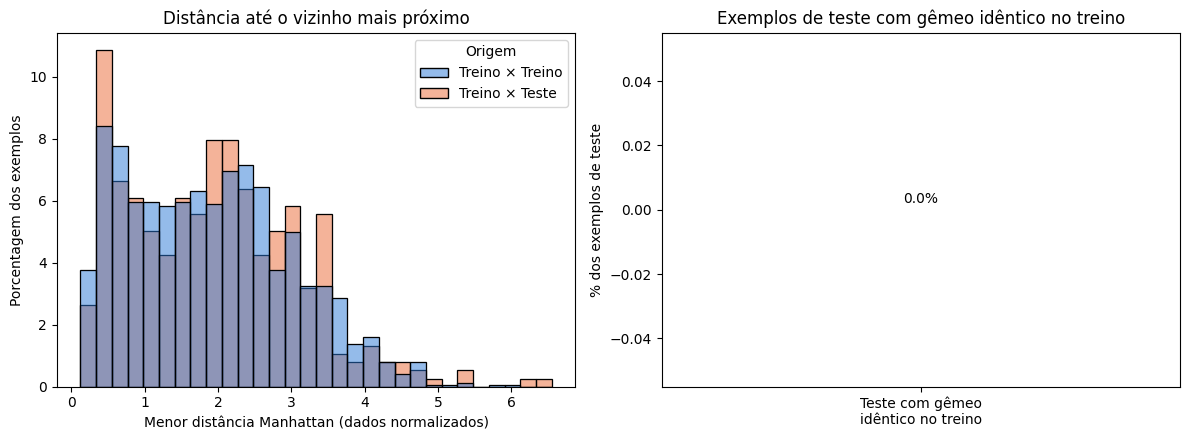

In [16]:
normalizador = MinMaxScaler().fit(X_treino)
treino = normalizador.transform(X_treino)
teste = normalizador.transform(X_teste)

vizinhos = NearestNeighbors(n_neighbors=1, metric="manhattan", n_jobs=-1).fit(treino)
treino_treino = vizinhos.kneighbors()[0].ravel()
treino_teste = cdist(treino, teste, "cityblock").min(axis=0)

dist = pd.concat([
    pd.DataFrame({"valor": treino_treino, "Origem": "Treino × Treino"}),
    pd.DataFrame({"valor": treino_teste, "Origem": "Treino × Teste"}),
], ignore_index=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(
    data=dist, x="valor", hue="Origem", stat="percent", common_norm=False,
    bins=30, alpha=0.5, ax=ax1,
    palette={"Treino × Treino": "#2a78d6", "Treino × Teste": "#eb6834"},
)
ax1.set(
    title="Distância até o vizinho mais próximo",
    xlabel="Menor distância Manhattan (dados normalizados)",
    ylabel="Porcentagem dos exemplos",
)

percentual_gemeos = (treino_teste == 0).mean() * 100
barras = ax2.bar(["Teste com gêmeo\nidêntico no treino"], [percentual_gemeos],
                 color="#eb6834", width=0.4)
ax2.bar_label(barras, fmt="%.1f%%", padding=3)
ax2.set(title="Exemplos de teste com gêmeo idêntico no treino",
        ylabel="% dos exemplos de teste")

plt.tight_layout()
plt.show()

No gráfico acima, as barras de cor **azul** representam as distâncias internas do treino, já as barras **laranjas** representam as distâncias entre o treino e o teste. Visualmente, as barras majoritariamente sobrepostas, somadas à porcentagem de **0,00% de gêmeos idênticos no teste** (distância igual a zero), são fortes indicadores de que os dados estão bem distribuídos.

Adicionalmente, para aferir a qualidade do split, aplicou-se o teste não paramétrico de **Mann-Whitney** (`mannwhitneyu` com hipótese alternativa `alternative="less"`) [7], cuja hipótese nula estabelece que as duas distribuições de distâncias são iguais, contra a alternativa de que as distâncias internas do treino são menores que as distâncias entre teste e treino.

In [17]:
# Função suporte para conclusões
def conclusao(pvalor, significancia):

    print("p-valor =", pvalor)

    print()

    if pvalor < significancia:
        print("Conclusão do teste de hipótese: \033[31mdevemos rejeitar H0\033[0m")
    else:
        print("Conclusão do teste de hipótese: \x1b[32mnão devemos rejeitar H0\x1b[0m")

# Realiza o teste de hipótese Mann-Whitney
p_valor = mannwhitneyu(treino_treino, treino_teste, alternative="less").pvalue

conclusao(p_valor, 0.05)

p-valor = 0.35127937122099584

Conclusão do teste de hipótese: não devemos rejeitar H0


Como resultado, obteve-se **$p = 0,3513$** ($p > 0,05$). Um p-valor elevado não prova que a divisão seja perfeita, mas indica que não há evidência estatística de deslocamento de distribuição ou vazamento de registros quase idênticos entre treino e teste.

## **3. Análise Exploratória**

Toda a análise exploratória apresentada nesta seção foi conduzida **exclusivamente sobre o conjunto de treino** (`X_treino` e `y_treino`, com 1.507 exemplos), de modo que o conjunto de teste não influenciasse nenhuma decisão de pré-processamento ou seleção de atributos. A investigação segue uma sequência: avaliação do balanceamento do alvo, análise das distribuições marginais dos atributos, relação bivariada de variáveis numéricas com o alvo, matriz de correlação entre atributos, teste de associação categórica para etnia e, por fim, as decisões consolidadas de engenharia de atributos.

### **3.1 Balanceamento do alvo**

O gráfico de contagem abaixo ilustra a distribuição das cinco classes da variável alvo `TPD` no conjunto de treino:
* **Nscore:** 393 participantes (26,1%);
* **Cscore:** 299 participantes (19,8%);
* **Escore:** 285 participantes (18,9%);
* **Ascore:** 276 participantes (18,3%);
* **Oscore:** 254 participantes (16,9%).

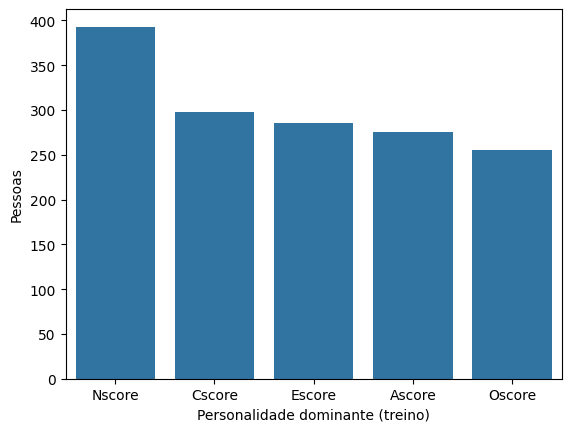

In [18]:
sns.countplot(x=y_treino, order=y_treino.value_counts().index)
plt.xlabel("Personalidade dominante (treino)")
plt.ylabel("Pessoas")
plt.show()

A classe majoritária (`Nscore`) possui cerca de 1,55 vez o tamanho da classe minoritária (`Oscore`), o que configura um desbalanceamento moderado. Embora esse cenário não inviabilize o cálculo da acurácia global, ele torna o uso da métrica **F1 macro** mais viável, pois ela avalia o desempenho em cada traço de personalidade com igual importância. Na prática, uma *baseline* que sempre prevê a classe mais frequente (`Nscore`) acerta cerca de 26% dos casos em acurácia, porém, obtém um F1 macro muito baixo, isso estabelece um patamar mínimo que os modelos induzidos precisam superar [4].

### **3.2 Distribuição dos atributos**

A fim de avaliar a composição da amostra sem consultar o teste, a tabela descritiva `consumo_drogas` foi filtrada pelos índices de `X_treino`. Os gráficos de contagem mostram padrões evidentes na distribuição das variáveis:

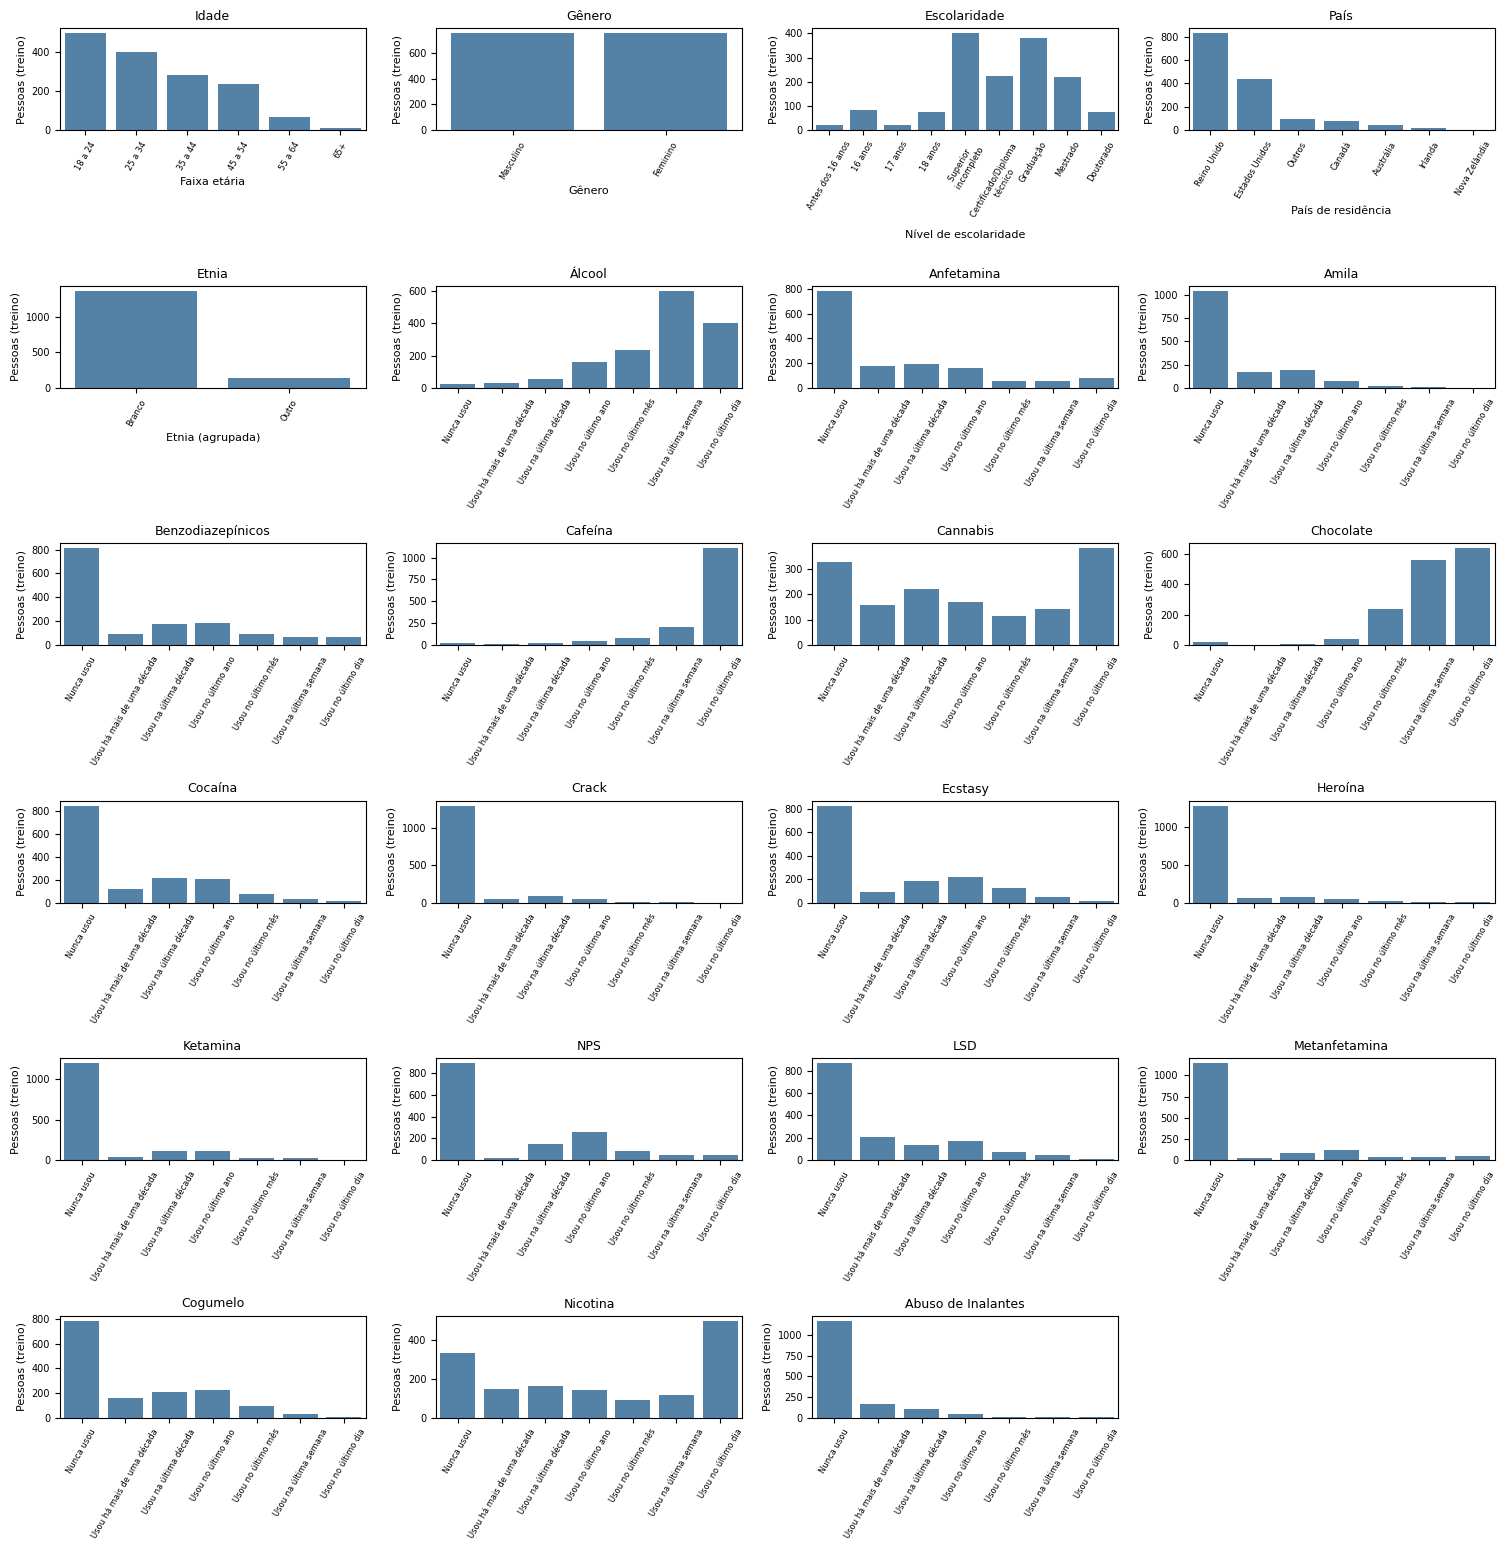

In [19]:
df_eda = consumo_drogas.loc[X_treino.index].copy()
df_eda["Etnia"] = X_treino["Etnia_Outro"].map({1: "Outro", 0: "Branco"})

variaveis = ["Idade", "Gênero", "Escolaridade", "País", "Etnia"] + [d for d in drogas if d in X_treino.columns]

ordens = {
    "Idade": idades,
    "Gênero": ["Masculino", "Feminino"],
    "Escolaridade": escolaridades,
}
for d in drogas:
    ordens[d] = list(value_map_freq.values())

rotulos_x = {
    "Idade": "Faixa etária",
    "Gênero": "Gênero",
    "Escolaridade": "Nível de escolaridade",
    "País": "País de residência",
    "Etnia": "Etnia (agrupada)",
}
rotulo_droga = ""

ncols = 4
nrows = math.ceil(len(variaveis) / ncols)
fig, eixos = plt.subplots(nrows, ncols, figsize=(ncols * 3.8, nrows * 2.6))

for ax, col in zip(eixos.flat, variaveis):
    ordem = ordens.get(col, df_eda[col].value_counts().index.tolist())
    sns.countplot(data=df_eda, x=col, order=ordem, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel(rotulos_x.get(col, rotulo_droga), fontsize=8)
    ax.set_ylabel("Pessoas (treino)", fontsize=8)
    ax.tick_params(axis="x", rotation=60, labelsize=6)
    ax.tick_params(axis="y", labelsize=7)

for ax in eixos.flat[len(variaveis):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Há um claro contraste entre substâncias lícitas cotidianas (`Cafeína`, `Chocolate`, `Álcool`), fortemente concentradas no uso recente, e substâncias ilícitas ou controladas (`Heroína`, `Crack`, `Metanfetamina`, `Ketamina`, `Abuso de Inalantes`), nas quais a barra dominante é `"Nunca usou"`. Para os modelos posteriormente induzidos, isso significa que grande parte das colunas de consumo é esparsa (repleta de zeros) e fortemente assimétrica, o que torna a escolha do método de normalização (como `MinMaxScaler` ou `MaxAbsScaler`) particularmente relevante.

Paralelamente, a amostra de treino apresenta equilíbrio entre gêneros (`Masculino` e `Feminino`), mas é fortemente concentrada em adultos jovens (faixas de `18 a 24` e `25 a 34` anos), indivíduos com ensino superior incompleto ou graduação, residentes no **Reino Unido** (seguido pelos Estados Unidos) e autodeclarados **Brancos** (com a categoria `Outro` representando menos de 9% do treino). Portanto, a amostra **não é representativa da população geral**, constituindo uma limitação importante para a generalização dos resultados.

### **3.3 Relação dos atributos com o alvo**

Para examinar como os escores comportamentais contínuos variam entre os diferentes traços dominantes de personalidade, foram construídos *boxplots* de `Impulsivo` e `SS` (*Sensation Seeking*) de acordo com a `TPD`. Em cada diagrama, a caixa delimita o intervalo interquartil (do 25º ao 75º percentil), a linha horizontal interna indica a mediana da classe, e os pontos isolados além das hastes representam valores atípicos (*outliers*).

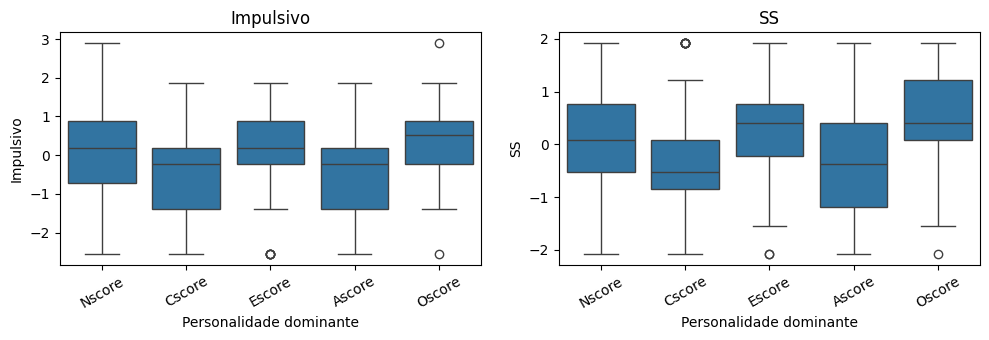

In [20]:
ordem_tpd = y_treino.value_counts().index.tolist()

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(eixos, ["Impulsivo", "SS"]):
    sns.boxplot(x=y_treino, y=X_treino[col], order=ordem_tpd, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Personalidade dominante")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Observando as medianas aproximadas em cada grupo no conjunto de treino:
* ***Sensation Seeking* (`SS`):** apresenta maior poder de discriminação visual entre os traços predominantes. Participantes com dominância em **`Oscore`** (mediana em torno de **$0,40$**) e **`Escore`** (mediana próxima de **$0,08$**) exibem níveis mais elevados de busca por sensações, ao passo que participantes dominantes em **`Cscore`** (mediana em torno de **$0,22$**) e **`Ascore`** (mediana próxima de **$0,22$**) concentram-se em valores mais baixos, enquanto **`Nscore`** ocupa uma posição intermediária (mediana próxima de **$0,08$**).
* **Impulsividade (`Impulsivo`):** exibe forte sobreposição entre as caixas das cinco classes, com medianas muito próximas (variando aproximadamente entre **$0,22$** para `Cscore` e `Ascore` até cerca de **$0,26$** para `Nscore` e `Oscore`).

Como as distribuições interquartis se sobrepõem amplamente, nenhum atributo isolado é capaz de separar perfeitamente as cinco classes de personalidade. Vale notar, contudo, que gráficos avaliam apenas uma variável por vez, não capturando interações multivariadas entre múltiplas substâncias e traços comportamentais.

### **3.4 Correlação entre atributos**

A dependência estatística entre todos os atributos de treino foi avaliada utilizando o **coeficiente de correlação de postos de Spearman** ($\rho$). Essa escolha justifica-se porque a maior parte das variáveis do problema é ordinal (escalas de consumo de 0 a 6, faixas etárias e escolaridade) ou binária, não satisfazendo a premissa de normalidade bivariada exigida pela correlação linear de Pearson. No mapa de calor (*heatmap*), tons quentes representam correlações positivas, tons frios indicam correlações negativas e o valor numérico de cada par é exibido diretamente na célula.

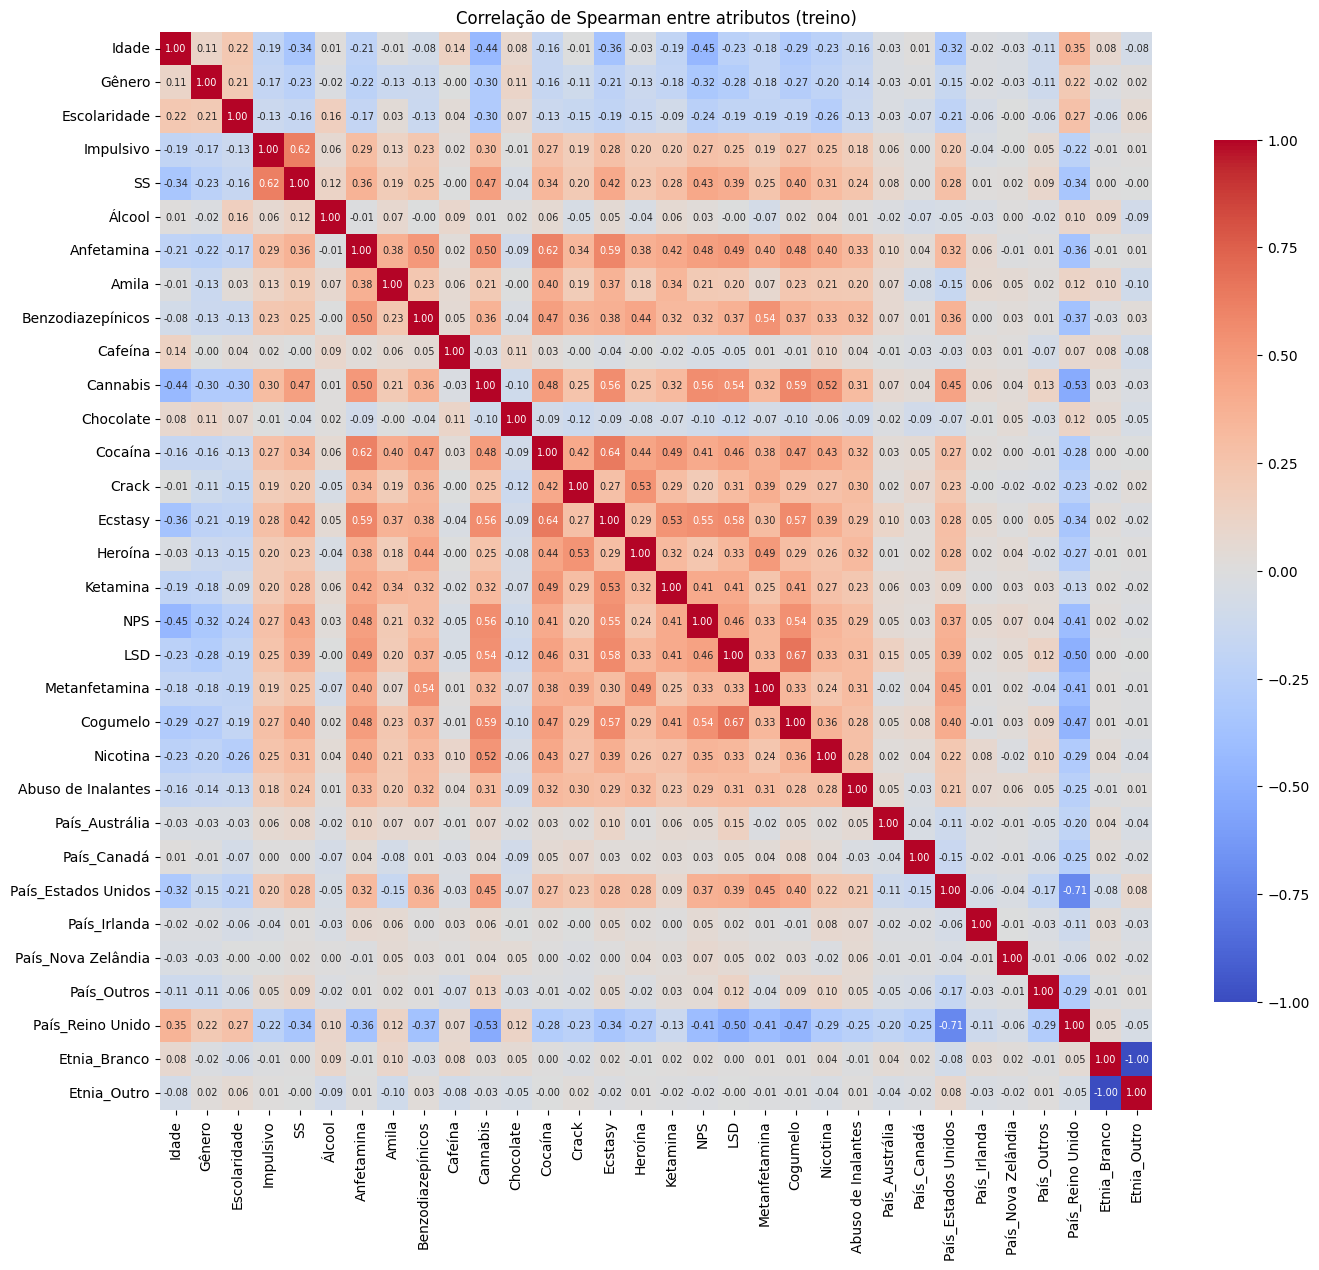

In [21]:
corr = X_treino.select_dtypes(include="number").corr(method="spearman")

plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.xticks(rotation=90)
plt.title("Correlação de Spearman entre atributos (treino)")
plt.show()

Os principais padrões identificados no conjunto de treino são:
* **Pares comportamentais e de policonsumo:** observa-se uma correlação positiva expressiva entre **`Impulsivo` e `SS` ($\rho = 0,62$)**, refletindo a proximidade psicológica entre impulsividade e busca por novidades. Entre as substâncias, destacam-se as associações positivas no grupo de psicodélicos e estimulantes recreativos, como **`LSD` e `Cogumelo` ($\rho = 0,67$)** e **`Cannabis` e `NPS` ($\rho = 0,56$)**, além de associações moderadas com `Ecstasy`.
* **Relação inversa com a idade:** `Idade` apresenta correlações negativas consistentes com diversas substâncias recreativas (como `Cannabis`, `Ecstasy`, `LSD` e `NPS`), indicando menor recência de uso entre participantes mais velhos.
* **Efeitos estruturais da codificação *one-hot*:** a correlação exata de **$-1,00$** entre `Etnia_Branco` e `Etnia_Outro` e a oposição forte entre `País_Reino Unido` e `País_Estados Unidos` decorrem diretamente do fato de serem categorias mutuamente exclusivas de uma mesma variável nominal, e não de fenômenos comportamentais independentes.

Neste trabalho adota-se o limiar de $|\rho| > 0,80$ para diagnosticar redundância severa entre atributos naturais. Nenhum par de variáveis contínuas, ordinais ou de consumo ultrapassou esse limite, evitando problemas graves de colinearidade direta. Ressalta-se, por fim, que correlação indica apenas coocorrência estatística na amostra e **não implica relação de causalidade**.

### **3.5 Associação entre etnia e alvo**

Como `Etnia` é uma variável categórica nominal e o alvo `TPD` também é categórico, a correlação de Spearman não é adequada para medir a relação entre eles. Em seu lugar, construímos uma tabela de contingência cruzando as categorias de etnia (`Branco` e `Outro`) com as cinco classes de personalidade no conjunto de treino e aplicamos o **teste qui-quadrado de independência ($\chi^2$)** via `scipy.stats.chi2_contingency` [7].

A hipótese nula ($H_0$) do teste estabelece que a etnia e o traço de personalidade dominante são estatisticamente independentes. Para que a aproximação pela distribuição qui-quadrado seja válida, exige-se que as frequências esperadas sob $H_0$ sejam superiores a 5 em todas as células da tabela - condição plenamente satisfeita em nossos dados, cuja **menor frequência esperada foi de 22,67**.


In [22]:
etnia_treino = X_treino["Etnia_Outro"].map({1: "Outro", 0: "Branco"})
tabela = pd.crosstab(etnia_treino, y_treino)
chi2, p, gl, esperados = chi2_contingency(tabela)

print(tabela)
print()
print(f"chi2={chi2:.2f}, gl={gl}, p={p:.4f}")
print("Menor frequência esperada:", round(esperados.min(), 2))

n = tabela.values.sum()
k, r = tabela.shape
print(f"V de Cramér = {np.sqrt(chi2 / (n * (min(k, r) - 1))):.3f}")

TPD          Ascore  Cscore  Escore  Nscore  Oscore
Etnia_Outro                                        
Branco          252     270     253     367     231
Outro            24      28      32      26      24

chi2=4.62, gl=4, p=0.3280
Menor frequência esperada: 22.67
V de Cramér = 0.055


Os resultados obtidos no treino foram:
* **Estatística $\chi^2$:** $4,62$ (com $4$ graus de liberdade);
* **p-valor:** $0,328$ (muito acima do nível de significância usual de $0,05$, não permitindo rejeitar a hipótese de independência);
* **V de Cramér:** $0,055$ (métrica normalizada entre $0$ e $1$ que mede a magnitude da associação independentemente do tamanho amostral; valores abaixo de $0,10$ indicam associação desprezível).

Esses números demonstram que a associação estatística entre etnia e personalidade dominante é extremamente fraca na amostra.

### **3.6 Decisões sobre os atributos**

Com base nas evidências reunidas na análise exploratória, foram tomadas três decisões para o conjunto de entrada antes da etapa de modelagem:

1. **Remoção das colunas de etnia (`Etnia_Branco` e `Etnia_Outro`):** ambas as colunas foram excluídas tanto de `X_treino` quanto de `X_teste` por dois motivos: (i) a associação estatística praticamente nula com o alvo ($\chi^2 = 4,62$, $p = 0,328$, $V = 0,055$) e (ii) o caráter sensível do atributo, cuja remoção previne qualquer risco ético de discriminação algorítmica - justificativa que se sustenta independentemente do resultado estatístico.
2. **Manutenção dos demais 30 atributos:** a remoção se limitou a Semeron, que funciona como controle e tem variância quase nula, e a Etnia, por seu caráter sensível e pela associação fraca com o alvo. A redução de dimensionalidade foi deixada para a otimização, em que o Optuna decide se usa PCA e quantos componentes, para cada modelo.
3. **Redução de dimensionalidade delegada à otimização:** em vez de impor uma redução fixa, a Análise de Componentes Principais (PCA) [9] foi incorporada como uma etapa opcional dentro das *pipelines* de modelagem, permitindo que o otimizador Optuna decida, para cada algoritmo, se a projeção em componentes principais melhora ou não a validação cruzada.

Ao final desse processo, `X_treino` (1.507 linhas) e `X_teste` (377 linhas) permanecem com **30 atributos de entrada**.

In [23]:
# Remove as colunas que diziam respeito a etnia
X_treino = X_treino.drop(columns=["Etnia_Branco", "Etnia_Outro"])
X_teste = X_teste.drop(columns=["Etnia_Branco", "Etnia_Outro"])

# Imprime o formato dos DFs de treino e teste
print(X_treino.shape, X_teste.shape)

(1507, 30) (377, 30)


## **4. Modelagem**

Nesta seção, foram induzidos cinco algoritmos de classificação supervisionados para prever o traço de personalidade dominante a partir dos 30 atributos selecionados. Ela segue uma linha direta: (1) construção do *Baseline*; (2) otimização de hiperparâmetros e pré-processamento de cada modelo via validação cruzada no conjunto de treino (`Optuna`); (3) comparação entre os candidatos; (4) análise de sensibilidade à semente de partição da validação cruzada; e (5) definição explícita da regra de escolha do modelo vencedor **antes** de qualquer contato com os dados de teste.

Todas as estimativas de desempenho foram obtidas por meio de **validação cruzada estratificada de 5 folds** (`StratifiedKFold(n_splits=5, shuffle=True, random_state=61888)`) [6], garantindo que as cinco classes mantenham exatamente as mesmas proporções em cada partição de treino e validação.

Adotou-se **F1 macro** como métrica principal de avaliação e otimização [4]. Para cada classe $c \in \{1, \dots, 5\}$, a precisão ($P_c$) mede a proporção de previsões corretas entre todas as vezes em que o modelo previu a classe $c$, enquanto a revocação ou *recall* ($R_c$) mede a proporção de exemplos reais da classe $c$ que foram corretamente recuperados [4]. O escore $F_{1,c}$ é a média harmônica entre precisão e revocação [4]:

$$F_{1,c} = \frac{2 \cdot P_c \cdot R_c}{P_c + R_c}$$

O **F1 macro** corresponde à média aritmética simples dos cinco escores por classe ($F_{1,\text{macro}} = \frac{1}{5}\sum_{c=1}^{5} F_{1,c}$), atribuindo exatamente o mesmo peso tanto à classe majoritária (`Nscore`) quanto à minoritária (`Oscore`) [4].

### **4.1 Indução do modelo Baseline**

Para começar, avalia-se um classificador de linha de base (`DummyClassifier(strategy="most_frequent")`) [6], que ignora completamente os atributos de entrada e sempre prevê a classe mais frequente no conjunto de treino (`Nscore`).

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE_ALEATORIA)

baseline = DummyClassifier(strategy="most_frequent")
scores = cross_val_score(baseline, X_treino, y_treino, cv=cv, scoring="f1_macro")

print(f"Baseline (classe mais frequente): F1 macro = {scores.mean():.3f} ± {scores.std():.3f}")

Baseline (classe mais frequente): F1 macro = 0.083 ± 0.000


Esse modelo servirá como piso mínimo de desempenho: qualquer algoritmo útil precisa superar significativamente esse patamar para demonstrar que obteve padrão preditivo real dos dados. Na validação cruzada estratificada de 5 folds, a linha de base obteve **F1 macro de $0,083 \pm 0,000$**. Esse valor baixo ocorre porque o modelo atinge revocação de $1,00$ apenas para `Nscore` (com precisão igual à sua proporção de ~26%), mas obtém $F_1 = 0,000$ nas outras quatro classes, resultando em média próxima de $0,083$ [4]. O desvio padrão é nulo porque a estratégia sempre prevê a mesma classe em todos os folds e a estratificação mantém as proporções idênticas entre as partições.

### **4.2 Otimização com Optuna: conceitos**

Para buscar boas combinações de pré-processamento e hiperparâmetros sem ter que fazer buscas exaustivas e computacionalmente inviáveis, foi utilizada a biblioteca `Optuna` [10]. No `Optuna`, cada execução de uma configuração candidata é chamada de **trial** (tentativa), o conjunto de tentativas forma um **estudo** (*study*), o espaço de valores permitidos para cada parâmetro constitui o **espaço de busca**, e a função Python avaliada em cada tentativa é a **função objetivo**.

Utilizamos o amostrador bayesiano **TPE (*Tree-structured Parzen Estimator*)** (`TPESampler(seed=61888)`) [10] configurado na direção `"maximize"`. Diferentemente de uma busca aleatória, o TPE modela probabilisticamente as regiões do espaço de busca que produziram os maiores valores de F1 macro nas tentativas anteriores e concentra as novas amostras nas regiões mais promissoras. Fixamos o orçamento em **100 tentativas (*trials*)** por modelo - tornando-o equilibrado entre cobertura do espaço de busca e tempo de execução - e travou-se a semente do amostrador para assegurar reprodutibilidade. A cada tentativa, a função objetivo constrói uma *pipeline* completa e retorna a média do F1 macro nos 5 folds de validação.

### **4.3 Funções compartilhadas: normalização e PCA**

Para que todos os modelos baseados em distâncias ou produtos internos fossem avaliados igualmente, definiu-se uma função auxiliar (`sugere_normalizador`) que permite ao `Optuna` escolher entre quatro estratégias de pré-processamento de escala [6]:
* **`StandardScaler`:** centraliza cada atributo subtraindo sua média e divide pelo seu desvio padrão ($\mu = 0, \sigma = 1$);
* **`MinMaxScaler`:** reescala linearmente cada atributo para o intervalo $[0, 1]$;
* **`MaxAbsScaler`:** divide cada atributo pelo seu valor absoluto máximo, preservando os valores exatos de zero - fator importante para colunas esparsas de consumo de drogas nas quais `0` representa ausência de uso (`CL0`);
* **`passthrough`:** mantém os atributos em suas escalas originais, sem transformação.

Todas as transformações são encapsuladas dentro de um objeto `Pipeline` do `scikit-learn` [6]. Isso garante que os parâmetros de escala e de projeção sejam ajustados **exclusivamente sobre os 4 folds de treinamento** de cada iteração da validação cruzada e apenas aplicados ao fold de validação correspondente, eliminando qualquer risco de vazamento de dados durante a validação.

De maneira semelhante, a função `sugere_pca` permite ao `Optuna` decidir se aplica ou não a **Análise de Componentes Principais (PCA)** [9] e, em caso positivo, escolher o número de componentes principais entre `2` e `30`. O PCA projeta os dados em direções ortogonais que maximizam a variância explicada, podendo atenuar ruídos ou colinearidades [9]. Já para os modelos baseados em árvores de decisão (Árvore de Decisão, Floresta Aleatória e *Gradient Boosting*), a normalização não foi aplicada (`passthrough`), pois árvores tomam decisões olhando uma variável por vez e separando os dados por cortes de valor, de modo que mudar a escala das variáveis não altera essas divisões.

In [25]:
# Função que escolhe o método de normalização para um trial
def cria_normalizador(trial):
    tipo = trial.suggest_categorical("normalizador", ["padrao", "minmax", "maxabs"])
    if tipo == "minmax":
        return MinMaxScaler()
    if tipo == "maxabs":
        return MaxAbsScaler()
    return StandardScaler()

# Função que decide se a aplicação de PCA deve ocorrer
def cria_reducao(trial):
    if trial.suggest_categorical("reducao", ["nenhuma", "pca"]) == "pca":
        return PCA(n_components=trial.suggest_int("pca_componentes", 2, X_treino.shape[1]),
                   random_state=SEMENTE_ALEATORIA)
    return "passthrough"

# Função que o Optuna tenta maximizar ao longo das tentativas
def funcao_objetivo(trial, cria_pipeline):
    scores = cross_val_score(cria_pipeline(trial), X_treino, y_treino, cv=cv, scoring="f1_macro")
    return scores.mean()

# Função que imprime o estudo com melhores resultados
def mostra_estudo(estudo, nome):
    print(estudo.best_params)
    print(f"Melhor F1 macro = {estudo.best_value:.3f}")

Os intervalos de hiperparâmetros e de pré-processamento em cada tentativa (*trial*) do Optuna foram definidos para cobrir regiões plausíveis sem encarecer demais o tempo das 100 iterações por modelo:

* **Normalização e PCA:** incluímos três normalizadores (`StandardScaler`, `MinMaxScaler` e `MaxAbsScaler`) e a opção de aplicar `PCA` entre `2` e `30` componentes (ou não aplicar, via `passthrough`) para testar escalas adequadas a variáveis esparsas/ordinais e possíveis ganhos de rotação ou redução dimensional[cite: 21, 24].
* **Regressão logística:** o parâmetro `C` variou de `0,001` a `10.000` em escala logarítmica para abranger desde regularizações fortes até ajustes quase livres, embora o valor ótimo (`6584`) tenha ficado perto do limite superior e o teto de `10.000` não tenha sido ampliado por conta do prazo[cite: 21].
* **k-NN:** `n_neighbors` foi de `1` até `150` (ampliado após testes iniciais encostarem na borda) para comparar vizinhanças locais e globais, com `weights` (`uniform` ou `distance`) e `p` (`1` para Manhattan e `2` para Euclidiana)[cite: 21].
* **Árvore de decisão e Floresta aleatória:** as profundidades máximas (`max_depth` de `2` ou `3` até `20`) e os tamanhos mínimos de folha (`min_samples_leaf` até `40` na árvore e `20` na floresta) controlam o sobreajuste, junto a `criterion` (`gini` ou `entropy`), `n_estimators` (`50` a `300`) e `max_features` (`sqrt` ou `log2`) — com `max_depth = 19` na floresta ficando próximo do limite de `20`, mantido sem expansão devido ao tempo disponível[cite: 21, 25, 26].
* **Gradient boosting:** `learning_rate` (`0,01` a `0,3` em escala logarítmica), `max_iter` (`50` a `300`), `max_leaf_nodes` (`7` a `63`), `min_samples_leaf` (`5` a `50`) e `l2_regularization` (`0,0` a `10,0`) foram definidos em faixas amplas e equilibradas para regular árvores sequenciais sem excesso de custo computacional[cite: 21].

### **4.4 Regressão logística**

A **Regressão Logística** modela diretamente as probabilidades posteriores de cada uma das cinco classes de personalidade por meio da função *softmax* aplicada a combinações lineares dos atributos de entrada, prevendo a classe de maior probabilidade estimada [4, 6].

No espaço de busca, o hiperparâmetro **`C`** foi otimizado no intervalo contínuo de **$0,001$ a $10.000$ em escala logarítmica** (`log=True`), pois a força de regularização varia por ordens de grandeza. O parâmetro `C` corresponde ao inverso da intensidade da regularização $L_2$: valores pequenos de `C` impõem forte penalização aos coeficientes (gerando fronteiras de decisão mais simples), enquanto valores altos reduzem a penalização e permitem maior ajuste aos dados de treino. Manteve-se fixos `class_weight="balanced"` (para compensar o desbalanceamento moderado entre os traços) e `max_iter=2000` (critério numérico de convergência do otimizador).

In [26]:
def cria_pipeline_lr(trial):
    return Pipeline([
        ("normalizador", cria_normalizador(trial)),
        ("reducao", cria_reducao(trial)),
        ("modelo", LogisticRegression(C=trial.suggest_float("C", 1e-3, 1e4, log=True),
                                      max_iter=2000, class_weight="balanced")),
    ])

estudo_lr = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA),
)
estudo_lr.optimize(partial(funcao_objetivo, cria_pipeline=cria_pipeline_lr), n_trials=100)

mostra_estudo(estudo_lr, "Regressão logística")

{'normalizador': 'minmax', 'reducao': 'nenhuma', 'C': 6584.137123638251}
Melhor F1 macro = 0.333


Ao término das 100 tentativas, o Optuna selecionou a configuração com **normalização `MinMaxScaler`**, **sem PCA (`usar_pca=False`)** e **`C = 6584,12`**, alcançando **F1 macro de $0,333$** na validação cruzada com a semente original. A preferência pelo `MinMaxScaler` alinha-se ao fato de que a maioria dos atributos são contagens ordinais não negativas de consumo, ficando naturalmente limitadas ao intervalo $[0, 1]$ sem distorcer a esparsidade dos zeros.

### **4.5 k-NN**

O algoritmo de **$k$-vizinhos mais próximos (*k-NN*)** é um método não paramétrico baseado em instâncias que classifica um novo participante por meio da votação entre os $k$ exemplos mais próximos no espaço de atributos [6]. Como o cálculo de vizinhança depende diretamente de distâncias geométricas, a normalização dos atributos é indispensável para impedir que variáveis com maior amplitude numérica dominem a métrica.

No espaço de busca do `KNeighborsClassifier` [6], explorou-se:
* **`n_neighbors` ($k$):** inteiro entre `1` e `150` - valores muito pequenos tornam o classificador sensível a ruídos locais, enquanto valores maiores suavizam as fronteiras de decisão. Esse limite superior foi ampliado para `150` após testes iniciais indicarem preferência por vizinhanças amplas;
* **`weights`:** `"uniform"` (todos os $k$ vizinhos têm peso igual) ou `"distance"` (vizinhos mais próximos exercem maior influência na votação, ponderados pelo inverso da distância);
* **`p`:** métrica de Minkowski com **`p = 1`** (distância de Manhattan) ou **`p = 2`** (distância Euclidiana).

In [27]:
def cria_pipeline_knn(trial):
    return Pipeline([
        ("normalizador", cria_normalizador(trial)),
        ("reducao", cria_reducao(trial)),
        ("modelo", KNeighborsClassifier(
            n_neighbors=trial.suggest_int("n_neighbors", 1, 150),
            weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
            p=trial.suggest_categorical("p", [1, 2]),
        )),
    ])

estudo_knn = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA),
)
estudo_knn.optimize(partial(funcao_objetivo, cria_pipeline=cria_pipeline_knn), n_trials=100)

mostra_estudo(estudo_knn, "k-NN")

{'normalizador': 'minmax', 'reducao': 'nenhuma', 'n_neighbors': 42, 'weights': 'distance', 'p': 1}
Melhor F1 macro = 0.325



A melhor tentativa alcançou **F1 macro de $0,325$**, utilizando **normalização `MinMaxScaler`**, **sem PCA**, **`n_neighbors = 42`**, **`weights = "distance"`** e **`p = 1` (distância de Manhattan)** - métrica naturalmente mais robusta em espaços de 30 dimensões com muitas variáveis ordinais discretas.

### **4.6 Árvore de decisão**

A **Árvore de Decisão** particiona recursivamente o espaço de atributos por meio de regras binárias do tipo $x_j \le t$, escolhendo a cada nó o atributo e o limiar que maximizam a redução de impureza das classes [6]. No espaço de busca do `DecisionTreeClassifier` (com `class_weight="balanced"`), otimizou-se:
* **`criterion`:** função de impureza `"gini"` (índice de Gini) ou `"entropy"` (ganho de informação baseado na entropia de Shannon);
* **`max_depth`:** profundidade máxima da árvore entre `2` e `20`, controlando o nível de interação entre variáveis;
* **`min_samples_leaf`:** número mínimo de exemplos exigidos em cada nó folha, entre `1` e `50`, atuando como mecanismo de poda contra sobreajuste.

Árvores de decisão isoladas possuem alta variância e tendem a sobreajustar facilmente a ruídos da amostra de treino, o que motiva o uso de comitês de árvores nas seções seguintes.

In [28]:
def cria_pipeline_arvore(trial):
    return Pipeline([
        ("reducao", cria_reducao(trial)),
        ("modelo", DecisionTreeClassifier(
            criterion=trial.suggest_categorical("criterion", ["gini", "entropy"]),
            max_depth=trial.suggest_int("max_depth", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50),
            class_weight="balanced",
            random_state=SEMENTE_ALEATORIA,
        )),
    ])

estudo_arvore = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA),
)
estudo_arvore.optimize(partial(funcao_objetivo, cria_pipeline=cria_pipeline_arvore), n_trials=100)

mostra_estudo(estudo_arvore, "Árvore de decisão")

{'reducao': 'pca', 'pca_componentes': 5, 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 40}
Melhor F1 macro = 0.299


 Na otimização, a melhor configuração obteve **F1 macro de $0,299$**, combinando **PCA com 5 componentes principais**, critério **`"gini"`**, **`max_depth = 5`** e **`min_samples_leaf = 40`**. A escolha de uma redução drástica para apenas 5 componentes e folhas muito restritas indica que a árvore isolada precisou simplificar fortemente a representação para conter o sobreajuste, acabando por perder sinal discriminativo e ficando abaixo dos demais modelos.

### **4.7 Floresta aleatória**

A **Floresta Aleatória (*Random Forest*)** é um método de comitê (*ensemble*) baseado em *bagging* que treina dezenas ou centenas de árvores de decisão independentes sobre reamostragens com reposição (*bootstrap*) do conjunto de treino, sorteando ainda um subconjunto aleatório de atributos candidatos a cada divisão de nó [6]. A previsão final resulta da agregação dos votos de todas as árvores, reduzindo drasticamente a variância característica de uma árvore isolada.

No espaço de busca do `RandomForestClassifier` (com `class_weight="balanced"`), otimizou-se:
* **`n_estimators`:** número de árvores de decisão na floresta, entre `100` e `500`, controlando a estabilidade e o custo computacional do comitê;
* **`max_depth`:** profundidade máxima de cada árvore, entre `2` e `20`, limitando a complexidade das divisões e evitando sobreajuste;
* **`min_samples_leaf`:** número mínimo de exemplos exigidos em cada nó folha, entre `1` e `50`, atuando como trava contra sobreajuste;
* **`max_features`:** número de atributos sorteados como candidatos em cada divisão de nó, com opções `"sqrt"` ou `"log2"`, promovendo diversidade entre as árvores.

In [29]:
def cria_pipeline_rf(trial):
    return Pipeline([
        ("reducao", cria_reducao(trial)),
        ("modelo", RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 500),
            max_depth=trial.suggest_int("max_depth", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50),
            max_features=trial.suggest_categorical("max_features", ["sqrt", "log2"]),
            class_weight="balanced",
            random_state=SEMENTE_ALEATORIA,
            n_jobs=-1,
        )),
    ])

estudo_rf = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA),
)
estudo_rf.optimize(partial(funcao_objetivo, cria_pipeline=cria_pipeline_rf), n_trials=100)

mostra_estudo(estudo_rf, "Floresta aleatória")

{'reducao': 'pca', 'pca_componentes': 28, 'n_estimators': 181, 'max_depth': 19, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
Melhor F1 macro = 0.343


A melhor tentativa atingiu **F1 macro de $0,343$**, utilizando **PCA com 28 componentes**, **`n_estimators = 181`**, **`max_depth = 19`**, **`min_samples_leaf = 5`** e **`max_features = "sqrt"`**. A escolha de 28 componentes entre os 30 atributos originais quase não diminui o número de dimensões, mas gira os eixos dos dados mantendo ângulos retos entre eles, o que pode deixar os cortes da árvore mais diretos [9]. Nota-se que `max_depth = 19` ficou muito próximo da borda superior do intervalo (`20`); por restrição de tempo computacional, optou-se por não expandir esse limite, registrando esse ponto como uma limitação da busca.

### **4.8 Gradient boosting**

Como quinto candidato, foi incluído o **Gradient Boosting** por meio da implementação `HistGradientBoostingClassifier` do `scikit-learn` [6] (com `class_weight="balanced"`). 

Diferentemente da Floresta Aleatória - que treina árvores independentes em paralelo e combina seus resultados por votação -, o *Gradient Boosting* constrói **árvores de decisão rasas em sequência**, nas quais cada nova árvore é ajustada para corrigir os erros que o conjunto anterior ainda comete, seguindo a direção que mais reduz a perda de log-verossimilhança (o erro baseado nas probabilidades previstas para cada classe). A previsão final não é uma média simples, mas a **soma ponderada** das contribuições de todas as árvores da sequência.

No espaço de busca, otimizou-se:
* **`learning_rate`:** taxa de aprendizado entre $0,01$ e $0,3$ (em escala logarítmica), que controla o peso da contribuição de cada nova árvore; taxas menores exigem mais iterações, mas costumam generalizar melhor;
* **`max_iter`:** número máximo de iterações (árvores na sequência), entre `50` e `300`;
* **`max_leaf_nodes`:** número máximo de folhas por árvore, entre `8` e `64`, controlando a complexidade de cada aprendiz fraco;
* **`min_samples_leaf`:** número mínimo de amostras por folha, entre `5` e `500`;
* **`l2_regularization`:** penalização $L_2$ sobre os pesos das folhas, entre `0,001` e `10,0` (em escala logarítmica).

In [30]:
def cria_pipeline_gb(trial):
    return Pipeline([
        ("reducao", cria_reducao(trial)),
        ("modelo", HistGradientBoostingClassifier(
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            max_iter=trial.suggest_int("max_iter", 50, 300),
            max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 8, 64),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 500),
            l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10.0, log=True),
            class_weight="balanced",
            random_state=SEMENTE_ALEATORIA,
        )),
    ])

estudo_gb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA),
)
estudo_gb.optimize(partial(funcao_objetivo, cria_pipeline=cria_pipeline_gb), n_trials=100)

mostra_estudo(estudo_gb, "Gradient boosting")

{'reducao': 'pca', 'pca_componentes': 30, 'learning_rate': 0.016774188757634013, 'max_iter': 167, 'max_leaf_nodes': 33, 'min_samples_leaf': 17, 'l2_regularization': 8.048044511110403}
Melhor F1 macro = 0.336


A melhor tentativa obteve **F1 macro de $0,336$**, configurada com **PCA de 30 componentes**, **`learning_rate = 0,0168`**, **`max_iter = 167`**, **`max_leaf_nodes = 33`**, **`min_samples_leaf = 17`** e **`l2_regularization = 8,05`**. Quando o PCA mantém todos os 30 componentes, ele não diminui a quantidade de dimensões - apenas gira os eixos mantendo ângulos retos entre eles e cria novas variáveis sem correlação linear entre si antes de treinar as árvores [9].

### **4.9 Histórico da otimização**

Os gráficos de histórico de otimização (*optimization history*) permitem diagnosticar o comportamento do amostrador TPE ao longo das 100 tentativas de cada estudo [10]. Em cada figura, os pontos dispersos representam o F1 macro obtido em cada *trial* individual, enquanto a linha contínua preta acompanha o melhor valor acumulado até aquela iteração.

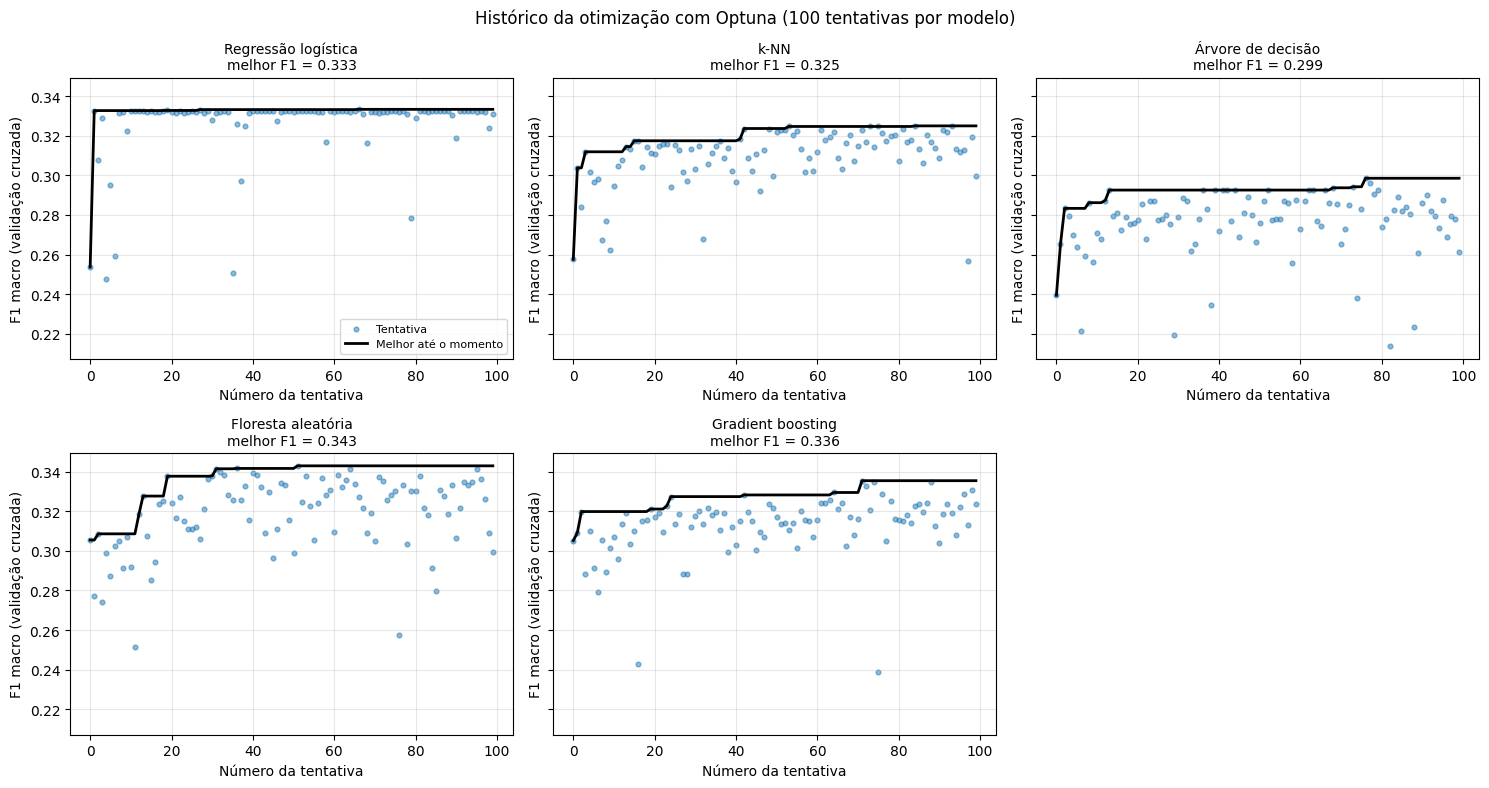

In [31]:
estudos_otim = {
    "Regressão logística": estudo_lr,
    "k-NN": estudo_knn,
    "Árvore de decisão": estudo_arvore,
    "Floresta aleatória": estudo_rf,
    "Gradient boosting": estudo_gb,
}

fig, eixos = plt.subplots(2, 3, figsize=(15, 8), sharey=True)

for ax, (nome, estudo) in zip(eixos.flat, estudos_otim.items()):
    df_t = estudo.trials_dataframe()
    df_t = df_t[df_t["state"] == "COMPLETE"]
    ax.scatter(df_t["number"], df_t["value"], s=12, alpha=0.5, label="Tentativa")
    ax.plot(df_t["number"], df_t["value"].cummax(), color="black", lw=2, label="Melhor até o momento")
    ax.set_title(f"{nome}\nmelhor F1 = {estudo.best_value:.3f}", fontsize=10)
    ax.set_xlabel("Número da tentativa")
    ax.set_ylabel("F1 macro (validação cruzada)")
    ax.grid(alpha=0.3)

eixos.flat[0].legend(fontsize=8, loc="lower right")
eixos.flat[-1].set_visible(False)

fig.suptitle("Histórico da otimização com Optuna (100 tentativas por modelo)", fontsize=12)
plt.tight_layout()
plt.show()

Nos cinco estudos, observa-se uma dispersão acentuada nas primeiras 15 a 25 tentativas - fase em que o amostrador explora amplamente o espaço de busca e sorteia configurações satisfatórias -, seguida pela formação de um **platô estável** a partir de aproximadamente metade das tentativas, indicando que a busca convergiu para uma região estável de desempenho sem ganhos relevantes nas iterações finais. Nos casos em que o ótimo se aproximou da borda do intervalo definido (como `max_depth = 19` na Floresta Aleatória e `C = 6584` próximo ao teto de $10.000$ na Regressão Logística), os limites estabelecidos foram mantidos em razão do custo computacional das 100 tentativas, discutindo esse aspecto na seção de limitações.

### **4.10 Comparação dos pipelines**

A tabela abaixo consolida o desempenho e as escolhas estruturais das cinco *pipelines* otimizadas na validação cruzada com a semente original (`61888`):

| Modelo | F1 Macro (Validação) | Normalização escolhida | Uso de PCA |
| :--- | :---: | :---: | :---: |
| **Floresta Aleatória** | **0,343** | Nenhuma (`passthrough`) | Sim (28 componentes) |
| **Gradient Boosting** | **0,336** | Nenhuma (`passthrough`) | Sim (30 componentes - rotação) |
| **Regressão Logística** | **0,333** | `MinMaxScaler` | Não |
| **k-NN** | **0,325** | `MinMaxScaler` | Não |
| **Árvore de Decisão** | **0,299** | Nenhuma (`passthrough`) | Sim (5 componentes) |
| *Linha de base (Dummy)* | *0,083* | *-* | *-* |

Embora todos os cinco modelos superem amplamente a linha de base ($0,083$), a leitura crítica dos resultados exige cautela: **as diferenças entre Floresta Aleatória ($0,343$), Gradient Boosting ($0,336$), Regressão Logística ($0,333$) e k-NN ($0,325$) são inferiores a $0,02$**, situando-se dentro da margem de variação típica entre folds da validação cruzada. Apenas a Árvore de Decisão isolada ($0,299$) destaca-se negativamente.

Além disso, os padrões escolhidos pelo Optuna revelam coerência estrutural: modelos lineares e baseados em distância (`Regressão Logística` e `k-NN`) se beneficiaram da normalização $[0, 1]$ do `MinMaxScaler` e preservaram os atributos originais, enquanto os comitês de árvores (`Floresta Aleatória` e `Gradient Boosting`) parecem ter se beneficiado da rotação ortogonal promovida pelo PCA de alta dimensão [9]. Como diferenças menores que o desvio padrão da validação não garantem superioridade real, investigamos a seguir a estabilidade dessas configurações.

### **4.11 Sensibilidade à semente da validação**

Como cada modelo foi otimizado ao longo de 100 tentativas sobre uma **única partição de validação cruzada** (gerada pela semente `61888`), a configuração vencedora de cada estudo está sujeita ao **viés de seleção otimista**: ao testar centenas de combinações na mesma divisão de folds, o melhor resultado tende a capturar parcialmente particularidades aleatórias daquela partição específica.

Para diagnosticar e reduzir esse efeito sem consultar o conjunto de teste, fixamos os melhores hiperparâmetros encontrados para cada um dos cinco modelos e reavaliamos cada *pipeline* em **cinco novas partições de validação cruzada estratificada**, geradas pelas sementes `0, 1, 2, 3` e `4` (sem executar o Optuna novamente). Antes de rodar o experimento, é estabelecido que a escolha final recairia sobre o modelo com **maior média de F1 macro nas cinco sementes**, avaliada exclusivamente no treino.

In [32]:
modelos = {
    "Regressão logística": (cria_pipeline_lr, estudo_lr),
    "k-NN": (cria_pipeline_knn, estudo_knn),
    "Árvore de decisão": (cria_pipeline_arvore, estudo_arvore),
    "Floresta aleatória": (cria_pipeline_rf, estudo_rf),
    "Gradient boosting": (cria_pipeline_gb, estudo_gb),
}

resultados = {}
for nome, (cria, estudo) in modelos.items():
    valores = []
    for s in range(5):
        cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
        pipe = cria(FixedTrial(estudo.best_params))
        valores.append(cross_val_score(pipe, X_treino, y_treino, cv=cv_s, scoring="f1_macro").mean())
    resultados[nome] = valores

for nome, valores in resultados.items():
    print(f"{nome}: média {np.mean(valores):.3f} ± {np.std(valores):.3f}")

Regressão logística: média 0.324 ± 0.005
k-NN: média 0.311 ± 0.006
Árvore de decisão: média 0.268 ± 0.012
Floresta aleatória: média 0.315 ± 0.007
Gradient boosting: média 0.306 ± 0.011


Os resultados obtidos nas cinco sementes foram:

| Modelo | Média ± Desvio Padrão |
| :---: | :---: | 
| **Regressão Logística** | **$0,324 \pm 0,005$** |
| **Floresta Aleatória** | **$0,315 \pm 0,007$** |
| **k-NN** | **$0,311 \pm 0,006$** | 
| **Gradient Boosting** | **$0,306 \pm 0,011$** |
| **Árvore de Decisão** | **$0,268 \pm 0,012$** | 

A comparação entre a semente original e as cinco novas sementes mostra um fenômeno muito importante para a escolha final: a **Floresta Aleatória caiu de $0,343$ para uma média de $0,315$** (uma queda de $0,028$), confirmando que seu desempenho inicial estava superestimado pelo ajuste aos folds da semente `61888`. O mesmo ocorreu com o *Gradient Boosting* (de $0,336$ para $0,306$).

C:\Users\giovanni2610060\AppData\Local\Temp\ipykernel_4376\849480294.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  eixo.boxplot([resultados[n] for n in nomes], labels=nomes, showmeans=True)


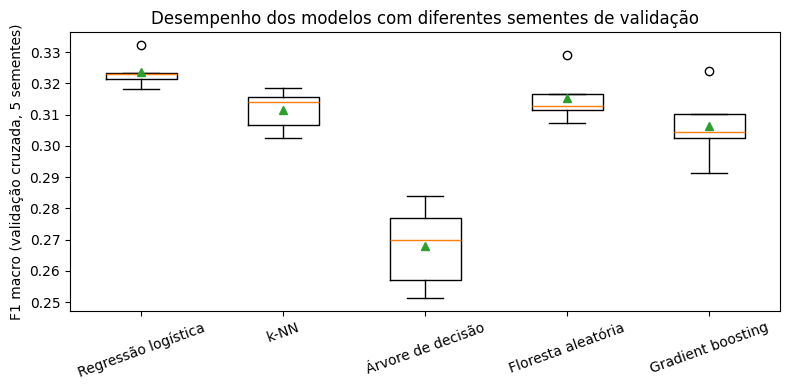

In [33]:
fig, eixo = plt.subplots(figsize=(8, 4))
nomes = list(resultados.keys())
eixo.boxplot([resultados[n] for n in nomes], labels=nomes, showmeans=True)
eixo.set_ylabel("F1 macro (validação cruzada, 5 sementes)")
eixo.set_title("Desempenho dos modelos com diferentes sementes de validação")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Em compensação, como mostra o *boxplot* comparativo, a **Regressão Logística apresentou a caixa mais estreita e posicionada acima de todos os demais modelos**, mantendo desempenho estável entre $0,318$ e $0,332$. Essa checagem reduz substancialmente o otimismo da seleção.

### **4.12 Regra de escolha do modelo**

Seguindo o critério definido após a checagem de sensibilidade: o modelo final escolhido é aquele que apresenta a **maior média de F1 macro** ao longo das cinco sementes de validação cruzada no conjunto de treino.

Com base nisso, a **Regressão Logística** ficou em primeiro lugar com média de **$0,324 \pm 0,005$**, ficando **$0,009$** acima da **Floresta Aleatória** ($0,315 \pm 0,007$). Como essa diferença é pequena e fica dentro da variação natural entre as sementes, os dois modelos empatam na prática e o critério da maior média serve como desempate. Além do número, a Regressão Logística se destaca por dois motivos:
1. **Simplicidade e estabilidade:** é um modelo mais direto e menos complexo que os conjuntos de árvores, além de ter apresentado a menor variação entre as cinco sementes ($\pm 0,005$);
2. **Leitura direta dos atributos:** como a configuração final não usa PCA, os pesos e a importância por permutação se aplicam diretamente aos 30 atributos originais, sem misturar variáveis em eixos transformados;

## **5. Avaliação final no conjunto de teste**

Com a escolha concluída, treinamos a *pipeline* vencedora (**Regressão Logística** com `MinMaxScaler`, `C = 6584,12` e `class_weight="balanced"`) sobre a totalidade dos **1.507 exemplos de treino** e a avaliamos **uma única vez** nos **377 exemplos inéditos do conjunto de teste**.

In [34]:
print(estudo_lr.best_params)

modelo_final = cria_pipeline_lr(FixedTrial(estudo_lr.best_params))
modelo_final.fit(X_treino, y_treino)

y_previsto = modelo_final.predict(X_teste)
print(f"F1 macro no teste = {f1_score(y_teste, y_previsto, average='macro'):.3f}")
print(classification_report(y_teste, y_previsto, digits=3))

{'normalizador': 'minmax', 'reducao': 'nenhuma', 'C': 6584.137123638251}
F1 macro no teste = 0.326
              precision    recall  f1-score   support

      Ascore      0.286     0.319     0.301        69
      Cscore      0.312     0.320     0.316        75
      Escore      0.309     0.239     0.270        71
      Nscore      0.458     0.388     0.420        98
      Oscore      0.282     0.375     0.322        64

    accuracy                          0.332       377
   macro avg      0.329     0.328     0.326       377
weighted avg      0.339     0.332     0.333       377



No conjunto de teste, o modelo obteve **F1 macro de $0,326$**, **acurácia global de $0,332$** e **F1 ponderado (*weighted*) de $0,333$** [4, 6]. A proximidade notável entre o F1 macro no teste ($0,326$) e a média obtida nas cinco sementes de validação cruzada ($0,324 \pm 0,005$) confirma que o protocolo de seleção controlou com sucesso o sobreajuste e que o modelo generaliza de forma consistente para dados nunca vistos.

O detalhamento das métricas por classe no conjunto de teste é apresentado abaixo [4]:
* **Nscore:** F1 = **$0,420$** (revocação = **$0,39$** - o maior índice de recuperação entre as cinco classes);
* **Oscore:** F1 = **$0,322$**;
* **Cscore:** F1 = **$0,316$**;
* **Ascore:** F1 = **$0,301$**;
* **Escore:** F1 = **$0,270$** (revocação = **$0,24$** - a classe de mais difícil recuperação).

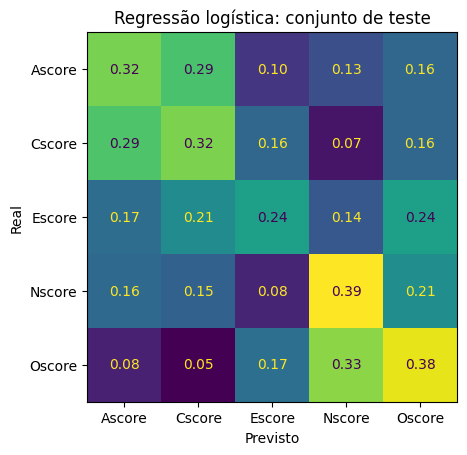

In [35]:
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_previsto, normalize="true", values_format=".2f", colorbar=False
)
plt.title("Regressão logística: conjunto de teste")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.show()

Para analisar os padrões de erro sem distorção pelo tamanho diferente de cada classe no teste, plotamos a **matriz de confusão normalizada por linha** (`normalize="true"`) [4, 6]. Nessa representação, cada linha corresponde à classe real do participante e os valores da diagonal principal indicam a proporção de acertos (revocação) de cada traço, enquanto as células fora da diagonal mostram como os erros se distribuem entre as classes previstas. Por exemplo, observa-se uma confusão simétrica expressiva entre **`Ascore` e `Cscore`** em ambos os sentidos (cerca de **$0,29$** dos exemplos reais de `Ascore` são previstos como `Cscore`, e aproximadamente **$0,29$** dos exemplos reais de `Cscore` são previstos como `Ascore`), além de **`Oscore` ser frequentemente confundido com `Nscore`** em cerca de **$0,33$** dos casos.

Adicionalmente, foi elaborado o gráfico abaixo que resume o desempenho em **F1 macro** dos cinco modelos avaliados na validação cruzada de 5 sementes (barras azuis com barras de erro), em comparação ao modelo *baseline* (linha tracejada cinza) e ao resultado final do modelo escolhido no conjunto de teste (ponto laranja).

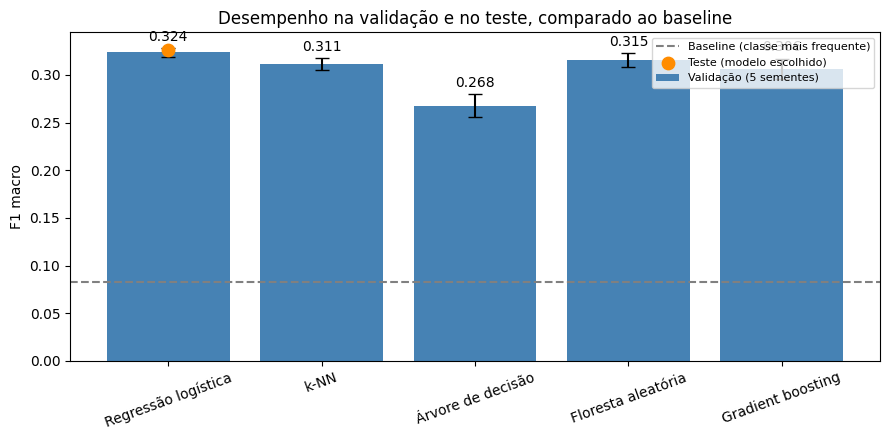

In [36]:
nomes = list(resultados.keys())
medias = [np.mean(resultados[n]) for n in nomes]
desvios = [np.std(resultados[n]) for n in nomes]

fig, eixo = plt.subplots(figsize=(9, 4.5))
barras = eixo.bar(nomes, medias, yerr=desvios, capsize=5, color="steelblue", label="Validação (5 sementes)")
eixo.bar_label(barras, fmt="%.3f", padding=3)

eixo.axhline(0.083, color="gray", linestyle="--", label="Baseline (classe mais frequente)")
eixo.scatter(["Regressão logística"], [0.326], color="darkorange", zorder=5, s=80, label="Teste (modelo escolhido)")

eixo.set_ylabel("F1 macro")
eixo.set_title("Desempenho na validação e no teste, comparado ao baseline")
eixo.legend(loc="upper right", fontsize=8)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Todos os modelos superam com folga o *baseline* (cerca de $0,083$), mostrando que há sinal preditivo acima do chute trivial, mas o desempenho geral ainda é moderado (na faixa de $0,27$ a $0,33$). Na validação multi-semente, **Regressão logística** ($0,324$), **Floresta aleatória** ($0,315$), **k-NN** ($0,311$) e **Gradient boosting** ficam próximos, enquanto a **Árvore de decisão** fica atrás ($0,268$). No teste, a Regressão logística mantém o nível da validação, indicando boa consistência sem sobreajuste grave.

### **5.1 Importância por permutação**

Para compreender quais variáveis mais sustentam as previsões da Regressão Logística no conjunto de teste, foi aplicado o método de **Importância por Permutação (*Permutation Importance*)** por meio da função `permutation_importance` do `scikit-learn` [6], configurado com **`n_repeats = 10`** repetições e métrica **`scoring = "f1_macro"`**. O procedimento embaralha aleatoriamente os valores de uma única coluna de `X_teste` por vez - destruindo sua relação com o alvo enquanto mantém todas as demais 29 colunas intactas, posteriormente medindo a queda média resultante no F1 macro [6]. Quanto maior a queda de desempenho, mais o modelo depende daquele atributo.

                   queda_media_f1  desvio_padrao
Impulsivo                  0.0334         0.0165
Ecstasy                    0.0307         0.0081
SS                         0.0290         0.0085
Benzodiazepínicos          0.0289         0.0140
País_Reino Unido           0.0225         0.0076
NPS                        0.0199         0.0108
Cocaína                    0.0197         0.0065
Idade                      0.0193         0.0120
LSD                        0.0186         0.0097
Álcool                     0.0183         0.0118
Cannabis                   0.0159         0.0148
Nicotina                   0.0153         0.0067
Cogumelo                   0.0128         0.0118
Chocolate                  0.0123         0.0092
Heroína                    0.0073         0.0059


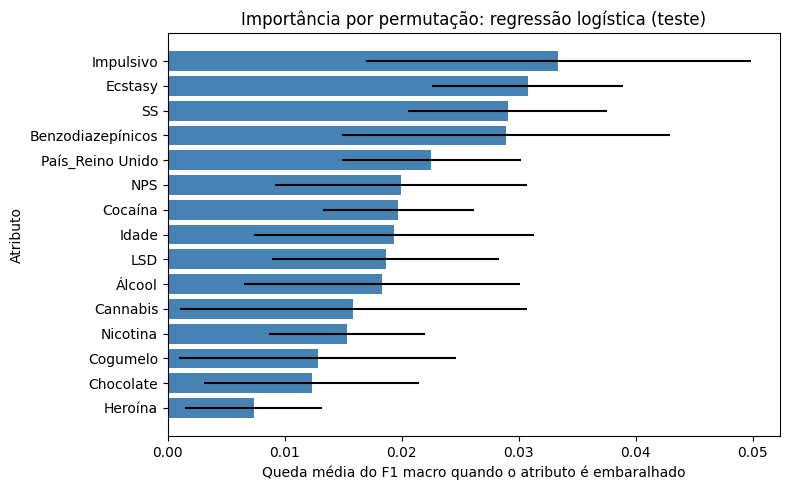

In [37]:
resultado = permutation_importance(
    modelo_final, X_teste, y_teste,
    scoring="f1_macro", n_repeats=10, random_state=SEMENTE_ALEATORIA, n_jobs=-1,
)

importancia = pd.DataFrame({
    "queda_media_f1": resultado.importances_mean,
    "desvio_padrao": resultado.importances_std,
}, index=X_teste.columns).sort_values("queda_media_f1", ascending=False)

print(importancia.head(15).round(4).to_string())

top = importancia.head(15)
plt.figure(figsize=(8, 5))
plt.barh(top.index[::-1], top["queda_media_f1"][::-1], xerr=top["desvio_padrao"][::-1], color="steelblue")
plt.xlabel("Queda média do F1 macro quando o atributo é embaralhado")
plt.ylabel("Atributo")
plt.title("Importância por permutação: regressão logística (teste)")
plt.tight_layout()
plt.show()

Como a *pipeline* final não utiliza PCA, cada coluna permutada corresponde diretamente a um atributo original interpretável. Os principais destaques no conjunto de teste são:
* **Topo do ranking:** **`Impulsivo`** lidera com queda média de **$0,033 \pm 0,017$**, seguido de perto por **`Ecstasy`** ($0,031$), **`SS`** ($0,029$), **`Benzodiazepínicos`** ($0,029$) e **`País_Reino Unido`** ($0,023$).
* **Substâncias de baixo impacto:** atributos como **`Heroína`** ($0,007$) situam-se na base da distribuição, com efeito residual próximo de zero.
* **Efeito da colinearidade:** **`Cannabis`** apresentou importância média modesta ($0,016 \pm 0,015$) e **`Nicotina`** ($0,015$). Como visto na matriz de Spearman, `Cannabis` possui forte correlação positiva com `NPS` ($\rho = 0,56$) e com outros estimulantes/alucinógenos; quando atributos são correlacionados, embaralhar apenas uma coluna permite que o modelo compense parcialmente a perda utilizando os atributos substitutos correlacionados, subestimando a importância individual de cada variável do grupo.

## **6. Conclusões e principais aprendizados**

### **6.1 Conclusão**

O modelo de **Regressão logística** induzido, na configuração final (`MinMaxScaler`, sem PCA, `C = 6584`, `class_weight="balanced"`), apresentou desempenho superior ao *baseline* da classe mais frequente ($0,326$ no teste e $0,324 \pm 0,005$ na validação de 5 sementes contra $0,083$, além de ficar acima do acaso uniforme de $0,200$), confirmando que o consumo de drogas e os traços de impulsividade e busca de sensações carregam sinal real sobre o traço de personalidade dominante, ainda que de forma parcial e com poder preditivo limitado.

Dentre os hiperparâmetros e modelos testados, a Regressão logística apresentou o melhor equilíbrio entre estabilidade nas cinco sementes e simplicidade interpretativa sem PCA, enquanto os conjuntos de árvores (Floresta aleatória e Gradient boosting) obtiveram médias próximas na validação, mas mostraram maior sensibilidade à mudança de semente. Apesar da melhora em relação ao *baseline*, o erro de classificação ainda é elevado e varia entre os traços - com destaque positivo para `Nscore` e maior confusão entre `Ascore`, `Cscore` e `Escore` -, indicando que outros fatores não capturados pelo dataset também influenciam a personalidade dominante e que o resultado não justifica uso prático ou diagnóstico individual.

Algumas limitações observadas ao longo do trabalho são: na otimização com Optuna, com alguns hiperparâmetros (`max_depth` na Floresta aleatória e `C` na Regressão logística) próximos às bordas do espaço de busca por conta do prazo. Ademais, trata-se de um único dataset, uma amostra não representativa da população geral, com etnia removida por associação estatística fraca e por cautela ética com atributo sensível. Vale a ressalva de que importância por permutação e correlação indicam associação no modelo.

### **6.2 Principais aprendizados**

Durante a elaboração desse trabalho foi possível pôr em prática (e por consequência aprender de verdade) muitas das coisas ensinadas em sala de aula. Alguns dos conceitos que foram solidificados durante a formulação desse trabalho são uma nova percepção sobre vazamento de dados (separar o teste antes da análise exploratória, remover os cinco escores de personalidade usados para criar o alvo e manter normalização e PCA dentro do *pipeline*), pois foi um trabalho que pedia um processo rigoro à respeito disso; outras métricas avaliativas de algoritmos de classificação; utilização da matriz de confusão normalizada em problemas multiclasse e a verificação de sensibilidade à semente antes de avaliar o teste. Também houve um amadurecimento no que diz respeito à parte de programação, como melhor entendimento do uso das bibliotecas `scikit-learn`, `pandas`, `scipy` e `Optuna`, na estruturação de experimentos e na leitura crítica dos resultados.

## **Nota sobre o uso de IA**

Durante o desenvolvimento deste trabalho foram utilizadas as IAs **Claude (Anthropic)** e **Gemini (Google)** em diferentes frentes. O Claude foi empregado principalmente como auxílio na programação, com ajuda na escrita de código em `Pandas`, `NumPy`, `SciKit-Learn` e `Optuna`, apoio na estruturação dos pipelines de modelagem, na formulação da maioria dos gráficos com `Seaborn` e `Matplotlib`, na depuração de erros de execução e no esclarecimento de dúvidas conceituais, como os testes estatísticos e as métricas utilizadas. O Gemini foi utilizado sobretudo na revisão dos textos em Markdown, para conferir gramática, coesão e clareza da redação. Além disso, as IAs foram utilizadas como forma de validação de ideias e decisões tomadas ao longo do trabalho, assim como a revisão final do notebook. Todas as sugestões foram avaliadas e conferidas por mim. As decisões metodológicas, a escolha das variáveis, a regra de avaliação e a interpretação dos resultados são de minha responsabilidade.

## *Referências*

[1] FEHRMAN, E.; MUHAMMAD, A. K.; MIRKES, E. M.; EGAN, V.; GORBAN, A. N. The Five Factor Model of Personality and Evaluation of Drug Consumption Risk. Cham: Springer, 2017. (Studies in Classification, Data Analysis, and Knowledge Organization).

[2] COSTA, P. T.; McCRAE, R. R. Revised NEO Personality Inventory (NEO-PI-R) and NEO Five-Factor Inventory (NEO-FFI) Professional Manual. Odessa, FL: Psychological Assessment Resources, 1992.

[3] FEHRMAN, E.; EGAN, V.; GORBAN, A. N.; LEVESLEY, J.; MIRKES, E. M.; MUHAMMAD, A. K. Drug Consumption (Quantified). UCI Machine Learning Repository, 2015. Disponível em: https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified. Acesso em: 14 nov. 2026.

[4] CASSAR, Daniel Roberto. ATP-203: Aprendizado de Máquina: Outras métricas e tipos de classificação. Notebook de aula, Ilum, Escola de Ciência, CNPEM, Campinas, 2026.

[5] McKINNEY, W. Data Structures for Statistical Computing in Python. In: Proceedings of the 9th Python in Science Conference, p. 56–61, 2010. Documentação do pandas disponível em: https://pandas.pydata.org/docs/. Acesso em: 20 nov. 2026.

[6] PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, v. 12, p. 2825–2830, 2011. Documentação disponível em: https://scikit-learn.org/stable/. Acesso em: 20 nov. 2026.

[7] VIRTANEN, P. et al. SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python. Nature Methods, v. 17, p. 261–272, 2020. Documentação disponível em: https://docs.scipy.org/doc/scipy/. Acesso em: 20 nov. 2026.

[8] CASSAR, Daniel Roberto. ATP-203: Aprendizado de Máquina: Seleção de atributos. Notebook de aula, Ilum, Escola de Ciência, CNPEM, Campinas, 2026.

[9] CASSAR, Daniel Roberto. ATP-203: Aprendizado de Máquina: Redução de dimensionalidade com PCA. Notebook de aula, Ilum, Escola de Ciência, CNPEM, Campinas, 2026.

[10] AKIBA, T.; SANO, S.; YANASE, T.; OHTA, T.; KOYAMA, M. Optuna: A Next-generation Hyperparameter Optimization Framework. In: Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining, p. 2623–2631, 2019. Documentação disponível em: https://optuna.readthedocs.io/. Acesso em: 20 nov. 2026.